# Лабораторная работа №1. Регрессия и метод главных компонент

Дисциплина: Системы искусственного интеллекта и машинное обучение

Выполнил: Ненашкин В. Д., гр. АВТ-313

## 1. Введение

### Цель работы

- Изучить основы линейной регрессии
- Построить простые модели регрессии
- Обучить модель на реальных данных и оценить её качество

### Задачи

- Прочитать данные, провести первичный анализ и подготовить выборки
- Построить матрицу корреляций и посчитать VIF
- Обучить линейную, лассо и гребневую регрессии, сравнить RMSE, R² и MAPE
- Устранить мультиколлинеарность методом главных компонент (PCA)
- Обучить те же модели на главных компонентах и сравнить метрики до и после PCA

### Данные

Работаем с набором California Housing Prices (Kaggle): 20 640 районов Калифорнии по переписи 1990 г. Одна строка - один район (блок-группа переписи). В строке записаны координаты, медианный возраст домов, суммарные числа комнат, спален, жителей и домохозяйств, медианный доход и близость к океану. Нужно предсказать медианную стоимость дома в районе: median_house_value. Файл housing.csv взят из https://github.com/ageron/handson-ml2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.tools.tools import add_constant

RANDOM_STATE = 42
DATA = 'housing.csv'

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
SEQ = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#0d366b'])
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.grid': True, 'grid.color': '#e1e0d9',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

В ячейке выше подключены библиотеки: pandas и numpy для таблиц и вычислений, matplotlib и seaborn для графиков, scikit-learn для разбиения выборки, предобработки, моделей, кросс-валидации и метрик, statsmodels для коэффициентов VIF и теста Бреуша-Пагана. Значение RANDOM_STATE = 42 передаётся во все функции со случайностью (разбиение, перемешивание при кросс-валидации), поэтому при повторном запуске числа получаются те же. Цвета и общий вид графиков задали один раз.

## 2. Описание датасета
### 2.1. Загрузка датасета


In [2]:
df = pd.read_csv(DATA, sep=',', header=0, encoding='utf-8')
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Файл прочитали функцией pd.read_csv с явными параметрами: значения разделены запятыми (sep=','), первая строка содержит названия столбцов (header=0), кодировка utf-8. Пустые поля в total_bedrooms pandas превращает в NaN. По первым строкам видно, что одна строка - один район, координаты записаны с точностью 0,01°, а цена в долларах.

In [3]:
print('Число наблюдений (строк):', df.shape[0])
print('Число столбцов:', df.shape[1])
df.info()

Число наблюдений (строк): 20640
Число столбцов: 10
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


В таблице 20 640 строк и 10 столбцов. Девять столбцов числовые (float64), а ocean_proximity строковый (str). В total_bedrooms 20 433 непустых значения, то есть 207 пропусков, в остальных столбцах пропусков нет.

In [4]:
TARGET = 'median_house_value'
num_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
                'total_bedrooms', 'population', 'households', 'median_income']
cat_features = ['ocean_proximity']

excluded = [col for col in df.columns if col not in num_features + cat_features]
print('Признаков:', len(num_features) + len(cat_features),
      f'(числовых {len(num_features)}, категориальных {len(cat_features)})')
print('Не входят в признаки:', excluded)

Признаков: 9 (числовых 8, категориальных 1)
Не входят в признаки: ['median_house_value']


Целевая переменная - median_house_value, медианная стоимость дома в районе в долларах. Признаками стали остальные девять столбцов: восемь числовых (num_features) и один категориальный ocean_proximity (cat_features). Матрицу признаков X и вектор y сформируем в разделе 3.1 после удаления пропусков.

### 2.2. Пропуски и дубликаты


In [5]:
missing = pd.DataFrame({'пропусков': df.isna().sum(),
                        'доля, %': df.isna().mean() * 100})
display(missing.round(2))
print('Полных дубликатов строк:', df.duplicated().sum())

,пропусков,"доля, %"
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,207,1.0
population,0,0.0
households,0,0.0
median_income,0,0.0
median_house_value,0,0.0
ocean_proximity,0,0.0


Полных дубликатов строк: 0


Пропуски есть только в total_bedrooms: 207 значений, то есть 1,0 % строк. Полных дубликатов нет (df.duplicated().sum() = 0), поэтому повторы удалять не нужно.

### 2.3. Описательные статистики


In [6]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


Признаки сильно различаются по масштабу: median_income измеряется единицами, а total_rooms и population доходят до десятков тысяч, поэтому перед регуляризацией и PCA их нужно масштабировать. У total_rooms среднее 2 635,8 при медиане 2 127, а у population среднее 1 425,5 при медиане 1 166 и максимуме 35 682 (Q3 = 1 725), то есть оба распределения скошены вправо. Цена меняется от 14 999 до 500 001 долл., среднее 206 856, медиана 179 700. Доход median_income лежит от 0,50 до 15,00, возраст домов housing_median_age от 1 до 52 лет, а отрицательные значения есть только у longitude.

In [7]:
caps = pd.DataFrame({
    'граничное значение': [df[TARGET].max(), df['housing_median_age'].max(),
                           df['median_income'].max(), df['median_income'].min()],
    'районов с этим значением': [(df[TARGET] == df[TARGET].max()).sum(),
                                 (df['housing_median_age'] == df['housing_median_age'].max()).sum(),
                                 (df['median_income'] == df['median_income'].max()).sum(),
                                 (df['median_income'] == df['median_income'].min()).sum()]},
    index=['median_house_value, максимум', 'housing_median_age, максимум',
           'median_income, максимум', 'median_income, минимум'])
caps['доля, %'] = caps['районов с этим значением'] / len(df) * 100
display(caps.round(4))
print('Самые частые значения цены:', df[TARGET].value_counts().head(3).to_dict())
print('Самые частые значения возраста домов:', df['housing_median_age'].value_counts().head(3).to_dict())

,граничное значение,районов с этим значением,"доля, %"
"median_house_value, максимум",500001.0000,965,4.6754
"housing_median_age, максимум",52.0000,1273,6.1676
"median_income, максимум",15.0001,49,0.2374
"median_income, минимум",0.4999,12,0.0581


Самые частые значения цены: {500001.0: 965, 137500.0: 122, 162500.0: 117}
Самые частые значения возраста домов: {52.0: 1273, 36.0: 862, 35.0: 824}


Максимумы цены и возраста домов похожи на срезы, то есть на ограничение сверху. Цену 500 001 долл. имеют 965 районов (4,68 %), а следующие по частоте цены - 137 500 (122 района) и 162 500 (117 районов). Возраст 52 года у 1 273 районов (6,17 %), следующее значение 36 лет у 862 районов. Доход median_income тоже ограничен с двух сторон: 15,0001 у 49 районов и 0,4999 у 12. Значение 500 001 читаем как 500 001 долл. и больше, поэтому у 965 районов настоящая цена неизвестна. Это учтём при анализе остатков в разделе 4.4.

### 2.4. Распределения признаков и целевой переменной


,коэффициент асимметрии
longitude,-0.30
latitude,0.47
housing_median_age,0.06
total_rooms,4.15
total_bedrooms,3.46
population,4.94
households,3.41
median_income,1.65
median_house_value,0.98


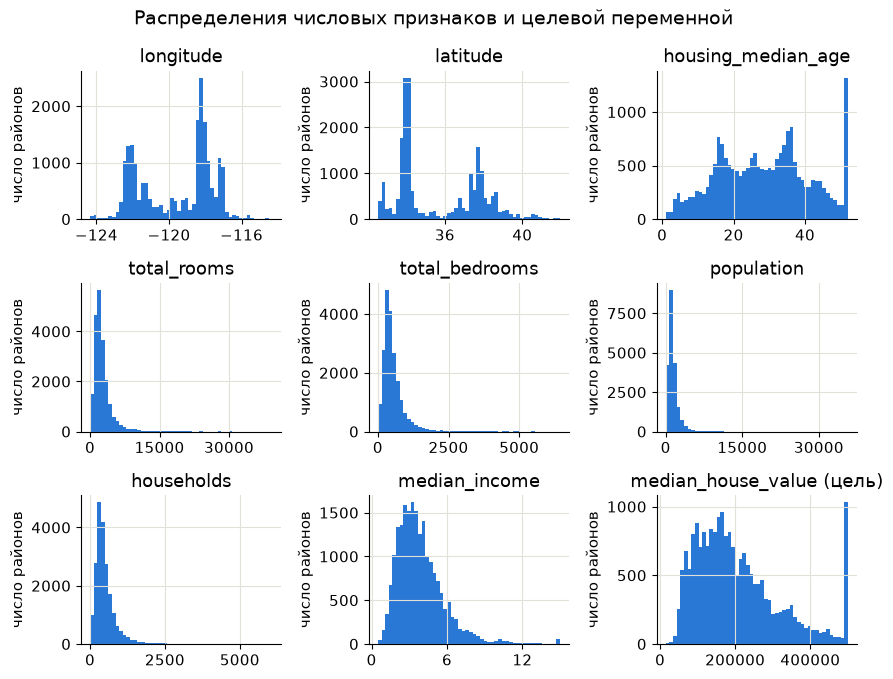

In [8]:
plot_cols = num_features + [TARGET]
display(df[plot_cols].skew().round(2).to_frame('коэффициент асимметрии'))

fig, axes = plt.subplots(3, 3, figsize=(8.8, 6.9))
for ax, col in zip(axes.ravel(), plot_cols):
    ax.hist(df[col].dropna(), bins=50, color=BLUE)
    ax.set_title(col)
    ax.set_ylabel('число районов')
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
axes[2, 2].set_title(TARGET + ' (цель)')
fig.suptitle('Распределения числовых признаков и целевой переменной', fontsize=14)
fig.tight_layout()
plt.show()

У total_rooms, total_bedrooms, population и households много малых значений и длинный правый хвост, коэффициенты асимметрии у них от 3,41 до 4,94. У median_income асимметрия 1,65, у цены 0,98. У housing_median_age и цены на правом краю виден отдельный высокий столбец, это срезы 52 года и 500 001 долл. У longitude и latitude по два пика: районы сосредоточены в двух областях, около -118° и 34° с. ш. и около -122° и 38° с. ш. Распределения далеки от нормального, а масштабы признаков различаются на порядки.

,районов,"доля, %"
ocean_proximity,,
<1H OCEAN,9136,44.26
INLAND,6551,31.74
NEAR OCEAN,2658,12.88
NEAR BAY,2290,11.09
ISLAND,5,0.02


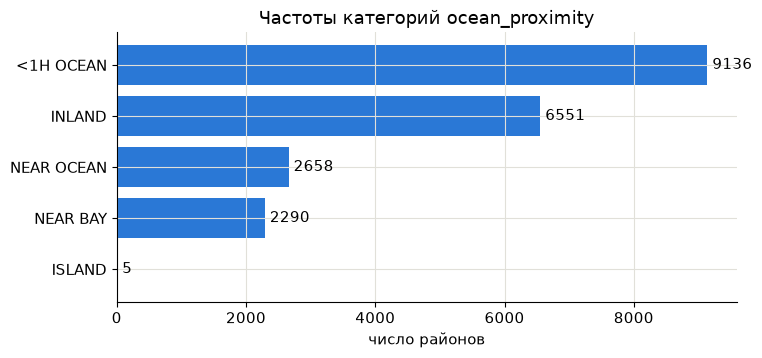

In [9]:
counts = df['ocean_proximity'].value_counts()
display(pd.DataFrame({'районов': counts, 'доля, %': (counts / len(df) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(counts.index[::-1], counts.values[::-1], color=BLUE)
for i, value in enumerate(counts.values[::-1]):
    ax.text(value + 80, i, str(value), va='center')
ax.set_xlabel('число районов')
ax.set_title('Частоты категорий ocean_proximity')
plt.show()

Признак ocean_proximity номинальный и состоит из пяти категорий: <1H OCEAN у 9 136 районов (44,26 %), INLAND у 6 551 (31,74 %), NEAR OCEAN у 2 658 (12,88 %), NEAR BAY у 2 290 (11,09 %) и ISLAND всего у 5 районов (0,02 %). Из-за редкой ISLAND при разбиении и кросс-валидации её может не оказаться в обучающей части. Это учтём при кодировании в разделе 3.3.

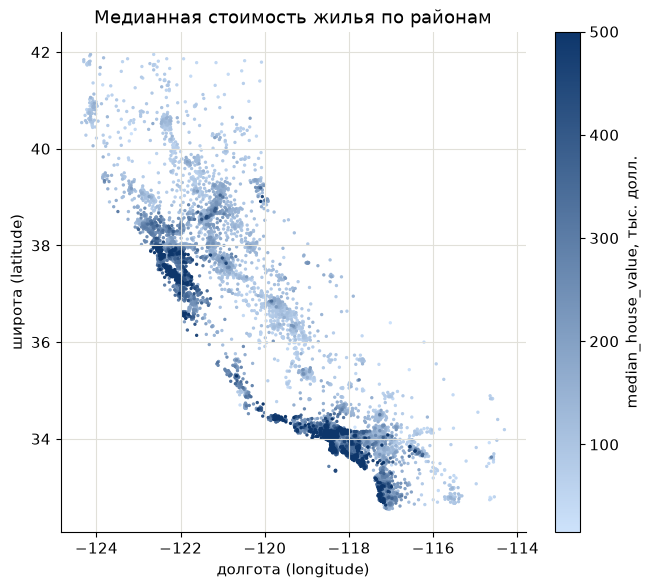

In [10]:
order = df[TARGET].sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 6.5))
points = ax.scatter(df.loc[order, 'longitude'], df.loc[order, 'latitude'],
                    c=df.loc[order, TARGET] / 1000, s=2, cmap=SEQ)
fig.colorbar(points, ax=ax, label='median_house_value, тыс. долл.')
ax.set_xlabel('долгота (longitude)')
ax.set_ylabel('широта (latitude)')
ax.set_title('Медианная стоимость жилья по районам')
plt.show()

Карту построили по координатам районов, цвет точки показывает медианную цену. Дорогие районы лежат вдоль побережья, внутренние в основном дешевле, а соседние точки обычно близки по цвету. Значит, цена зависит от местоположения, и это важно для выбора разбиения выборки в разделе 3.2.

### 2.5. Выбросы


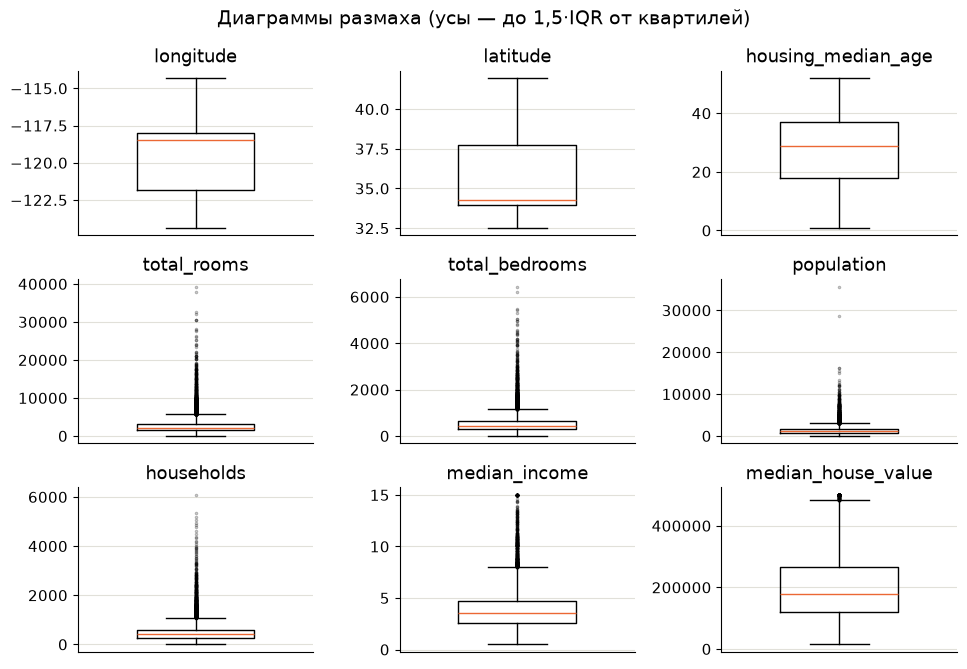

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(9.8, 6.8))
for ax, col in zip(axes.ravel(), plot_cols):
    ax.boxplot(df[col].dropna(), whis=1.5, widths=0.5,
               flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.3})
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle('Диаграммы размаха (усы — до 1,5·IQR от квартилей)', fontsize=14)
fig.tight_layout()
plt.show()

На ящике IQR = Q3 - Q1, линия внутри - медиана, а усы доходят до самых дальних значений в пределах 1,5·IQR от квартилей. Точки за усами по этому правилу (whis=1.5) считаются выбросами. У longitude, latitude и housing_median_age выбросов нет. У четырёх счётных признаков и у median_income выбросы только сверху, и их много. У цены точки за верхним усом - это районы дороже 482 412,5 долл., включая срез 500 001.

In [12]:
rows = []
for col in plot_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({'признак': col, 'Q1': q1, 'Q3': q3, 'нижняя граница': low, 'верхняя граница': high,
                 'выбросов': n_out, 'доля, %': n_out / df[col].notna().sum() * 100})
outliers = pd.DataFrame(rows).set_index('признак')
display(outliers.round(2))

any_outlier = np.zeros(len(df), dtype=bool)
for col in plot_cols:
    any_outlier |= ((df[col] < outliers.loc[col, 'нижняя граница']) |
                    (df[col] > outliers.loc[col, 'верхняя граница'])).to_numpy()
print('Строк хотя бы с одним выбросом:', any_outlier.sum(), f'({any_outlier.mean() * 100:.1f} %)')

,Q1,Q3,нижняя граница,верхняя граница,выбросов,"доля, %"
признак,,,,,,
longitude,-121.80,-118.01,-127.48,-112.33,0,0.00
latitude,33.93,37.71,28.26,43.38,0,0.00
housing_median_age,18.00,37.00,-10.50,65.50,0,0.00
total_rooms,1447.75,3148.00,-1102.62,5698.38,1287,6.24
total_bedrooms,296.00,647.00,-230.50,1173.50,1271,6.22
population,787.00,1725.00,-620.00,3132.00,1196,5.79
households,280.00,605.00,-207.50,1092.50,1220,5.91
median_income,2.56,4.74,-0.71,8.01,681,3.30
median_house_value,119600.00,264725.00,-98087.50,482412.50,1071,5.19


Строк хотя бы с одним выбросом: 3019 (14.6 %)


Выбросом считали значение ниже Q1 - 1,5·IQR или выше Q3 + 1,5·IQR. Таких значений у total_rooms 1 287 (6,24 %), у total_bedrooms 1 271 (6,22 %), у population 1 196 (5,79 %), у households 1 220 (5,91 %), у median_income 681 (3,30 %) и у median_house_value 1 071 (5,19 %). У координат и возраста домов выбросов 0, а хотя бы один выброс есть в 3 019 строках (14,6 %). Для нормального распределения за границы 1,5·IQR выходит около 0,7 % значений, у счётных признаков около 6 %, то есть правило отмечает длинный хвост. Нижние границы у счётных признаков отрицательные, поэтому все их выбросы сверху и относятся к крупным районам.

In [13]:
checks = pd.Series({
    'спален больше, чем комнат (total_bedrooms > total_rooms)': (df['total_bedrooms'] > df['total_rooms']).sum(),
    'домохозяйств больше, чем жителей (households > population)': (df['households'] > df['population']).sum(),
    'отрицательные значения (кроме долготы)': (df[plot_cols].drop(columns='longitude') < 0).sum().sum(),
}, name='строк')
display(checks.to_frame())
display(df[df['households'] > df['population']])
print('Наибольшее число комнат на одно домохозяйство:', round((df['total_rooms'] / df['households']).max(), 1))

,строк
"спален больше, чем комнат (total_bedrooms > total_rooms)",0
"домохозяйств больше, чем жителей (households > population)",3
отрицательные значения (кроме долготы),0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
5342,-118.44,34.04,16.0,18.0,6.0,3.0,4.0,0.5360,350000.0,<1H OCEAN
11849,-121.00,39.75,8.0,1116.0,214.0,27.0,39.0,2.5893,83000.0,INLAND
19522,-121.00,37.65,17.0,484.0,202.0,198.0,204.0,0.6825,187500.0,INLAND


Наибольшее число комнат на одно домохозяйство: 141.9


Проверили логические ограничения. Строк, где спален больше, чем комнат, нет, отрицательных значений (кроме долготы) тоже нет. Зато в 3 строках домохозяйств больше, чем жителей (например, 4 домохозяйства при 3 жителях). Так быть не может, поэтому эти строки считаем ошибочными и удалим в разделе 3. Наибольшее число комнат на домохозяйство равно 141,9.

Решение по выбросам.

Значения за границами 1,5·IQR не удаляем и не заменяем, потому что правило отмечает весь правый хвост, а не ошибки, и удаление затронуло бы 14,6 % строк. Срезанные значения цены (500 001) тоже оставляем. Удаляем только строки с пропусками и 3 противоречивые строки.

## 3. Подготовка данных
### 3.1. Удаление пропусков


In [14]:
df_clean = df.dropna()
print('Строк до удаления пропусков:', len(df))
print('После удаления пропусков:', len(df_clean), f'(удалено {len(df) - len(df_clean)})')

bad = df_clean['households'] > df_clean['population']
df_clean = df_clean[~bad]
print('После удаления противоречивых записей:', len(df_clean), f'(удалено {bad.sum()})')

Строк до удаления пропусков: 20640
После удаления пропусков: 20433 (удалено 207)
После удаления противоречивых записей: 20430 (удалено 3)


Пропуски удалили методом dropna(): было 20 640 строк, осталось 20 433, то есть удалено 207 строк (1,0 % данных). Затем убрали 3 строки, где домохозяйств больше, чем жителей, и для работы осталось 20 430 наблюдений.

In [15]:
X = df_clean[num_features + cat_features]
y = df_clean[TARGET]
print('X:', X.shape, ' y:', y.shape)

X: (20430, 9)  y: (20430,)


Матрица X содержит 20 430 строк и 9 столбцов (8 числовых признаков и ocean_proximity), вектор y содержит 20 430 значений цены. Кодирование и масштабирование к X здесь не применяем: они войдут в Pipeline и будут обучаться только на обучающей выборке.

### 3.2. Разделение на обучающую и тестовую выборки

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Обучающая выборка:', X_train.shape, ' тестовая:', X_test.shape)
print(f'Средняя цена: train {y_train.mean():.0f}, test {y_test.mean():.0f} долл.')
print(f'Доля районов с ценой 500 001: train {(y_train == 500_001).mean() * 100:.2f} %, '
      f'test {(y_test == 500_001).mean() * 100:.2f} %')
print('Районов ISLAND: train', (X_train['ocean_proximity'] == 'ISLAND').sum(),
      ' test', (X_test['ocean_proximity'] == 'ISLAND').sum())

Обучающая выборка: (16344, 9)  тестовая: (4086, 9)
Средняя цена: train 206679, test 207608 долл.
Доля районов с ценой 500 001: train 4.64 %, test 4.89 %
Районов ISLAND: train 4  test 1


Функция train_test_split с test_size=0.2 разделила данные в пропорции 80/20: в обучающей выборке 16 344 района, в тестовой 4 086. Параметр random_state=42 фиксирует перемешивание строк перед делением. Средняя цена в train 206 679 долл., в test 207 608 долл., доля районов с ценой 500 001 в train 4,64 %, в test 4,89 %. Категория ISLAND попала 4 районами в train и 1 районом в test. Тестовую выборку используем только для итоговой оценки.

In [17]:
_, X_test_same, _, _ = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
_, X_test_other, _, _ = train_test_split(X, y, test_size=0.2, random_state=0)
print('random_state=42 повторно — та же тестовая выборка:', X_test_same.index.equals(X_test.index))
print('random_state=0 — общих районов с исходной тестовой выборкой:',
      X_test.index.isin(X_test_other.index).sum(), 'из', len(X_test))

random_state=42 повторно — та же тестовая выборка: True
random_state=0 — общих районов с исходной тестовой выборкой: 849 из 4086


Параметр random_state задаёт начальное состояние генератора случайных чисел, поэтому при том же значении 42 тестовая выборка получается та же (проверка дала True) и результаты воспроизводимы. При random_state=0 с исходной тестовой выборкой совпадают 849 районов из 4 086 (20,8 %), то есть выборки получаются другие и метрики немного другие. Насколько меняются метрики, показано в разделе 4.3.5.

In [18]:
nn = NearestNeighbors(n_neighbors=1).fit(X_train[['latitude', 'longitude']])
dist, idx = nn.kneighbors(X_test[['latitude', 'longitude']])
neighbour_price = y_train.to_numpy()[idx[:, 0]]
neighbour_corr = np.corrcoef(y_test, neighbour_price)[0, 1]
same_coords = (dist[:, 0] == 0).mean() * 100
print(f'Корреляция цены тестового района и ближайшего к нему района из train: {neighbour_corr:.3f}')
print(f'Тестовых районов, у которых в train есть район с теми же координатами: {same_coords:.1f} %')

Корреляция цены тестового района и ближайшего к нему района из train: 0.862
Тестовых районов, у которых в train есть район с теми же координатами: 54.9 %


Временного порядка в данных нет: одна строка - один район, повторных наблюдений одного объекта и дубликатов нет. Но районы связаны пространственно. Корреляция цены тестового района и ближайшего района из train равна r = 0,862, а у 54,9 % тестовых районов в train есть район с теми же координатами. Поэтому случайное разбиение оценивает прогноз для новых районов на уже знакомой территории, а для другой территории такая оценка была бы оптимистичной. Тогда выборку надо делить по участкам карты.

### 3.3. Кодирование категориального признака

In [19]:
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[cat_features])
print('Категории:', list(encoder.categories_[0]))
print('Базовая (удалённая) категория:', encoder.categories_[0][encoder.drop_idx_[0]])
example = pd.DataFrame({'ocean_proximity': encoder.categories_[0]})
display(pd.DataFrame(encoder.transform(example), index=example['ocean_proximity'],
                     columns=encoder.get_feature_names_out()).astype(int))

Категории: ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']
Базовая (удалённая) категория: <1H OCEAN


,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
ocean_proximity,,,,
<1H OCEAN,0,0,0,0
INLAND,1,0,0,0
ISLAND,0,1,0,0
NEAR BAY,0,0,1,0
NEAR OCEAN,0,0,0,1


Категориальный признак у нас один, ocean_proximity, и он номинальный: категории не упорядочены. Кодирование числами 0-4 ввело бы в модель несуществующий порядок, поэтому используем one-hot, то есть на каждую категорию отдельный столбец из нулей и единиц. Параметр drop='first' удаляет столбец <1H OCEAN, и она становится базовой (все нули), иначе сумма пяти столбцов всегда равна 1 и повторяет свободный член. Коэффициент каждого из четырёх оставшихся столбцов показывает разницу в цене с <1H OCEAN. Параметр handle_unknown='ignore' нужен из-за редкой ISLAND (4 района в обучающей выборке): если категории не окажется в обучающей части, она кодируется нулями и ошибки нет. Параметр sparse_output=False возвращает обычный массив.

### 3.4. Масштабирование: fit, transform и fit_transform

In [20]:
scaler = StandardScaler()
scaler.fit(X_train[num_features])
train_scaled = scaler.transform(X_train[num_features])
test_scaled = scaler.transform(X_test[num_features])
scaling = pd.DataFrame({'среднее (fit)': scaler.mean_, 'СКО (fit)': scaler.scale_,
                        'среднее train после': train_scaled.mean(axis=0),
                        'СКО train после': train_scaled.std(axis=0),
                        'среднее test после': test_scaled.mean(axis=0),
                        'СКО test после': test_scaled.std(axis=0)}, index=num_features)
display(scaling.round(3))
same = np.allclose(StandardScaler().fit_transform(X_train[num_features]), train_scaled)
print('fit_transform(train) даёт то же, что fit(train) + transform(train):', same)

,среднее (fit),СКО (fit),среднее train после,СКО train после,среднее test после,СКО test после
longitude,-119.578,2.007,-0.0,1.0,0.020,0.993
latitude,35.639,2.138,0.0,1.0,-0.013,0.996
housing_median_age,28.597,12.613,-0.0,1.0,0.015,0.991
total_rooms,2629.011,2169.136,0.0,1.0,0.018,1.036
total_bedrooms,537.314,421.724,-0.0,1.0,0.007,0.996
population,1422.864,1136.633,0.0,1.0,0.010,0.985
households,498.768,382.254,-0.0,1.0,0.010,1.000
median_income,3.870,1.896,-0.0,1.0,0.003,1.008


fit_transform(train) даёт то же, что fit(train) + transform(train): True


Масштабируются восемь числовых признаков (StandardScaler), а столбцы ocean_proximity остаются нулями и единицами. Метод fit считает и запоминает среднее (mean_) и СКО (scale_) по обучающей выборке, transform применяет запомненные параметры по формуле z = (x - среднее) / СКО, а fit_transform делает оба шага сразу с тем же результатом (проверка: True). У train после преобразования среднее 0 и СКО 1. У test они приблизительно такие: средние от -0,013 до 0,020, СКО от 0,985 до 1,036. Так и должно быть, ведь test преобразован параметрами train и в настройке не участвовал.

### 3.5. Предобработка в ColumnTransformer

In [21]:
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features),
    ], verbose_feature_names_out=False)

prep = make_preprocessor().fit(X_train)
X_train_prep = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out(),
                            index=X_train.index)
print('Матрица признаков: до предобработки', X_train.shape, '-> после', X_train_prep.shape)
print(list(X_train_prep.columns))
print('Средние в StandardScaler равны средним train:',
      np.allclose(prep.named_transformers_['num'].mean_, X_train[num_features].mean()))

Матрица признаков: до предобработки (16344, 9) -> после (16344, 12)
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
Средние в StandardScaler равны средним train: True


ColumnTransformer объединяет две предобработки: StandardScaler для восьми числовых признаков и OneHotEncoder для ocean_proximity. После обучения на X_train получилась матрица 16 344 × 12 (8 стандартизованных и 4 фиктивных), а средние в StandardScaler совпали со средними train (True). Тестовая выборка в настройке не участвовала. Функция make_preprocessor() при каждом вызове создаёт новый необученный объект, поэтому у каждой модели своя предобработка. Масштабирование нужно, потому что штраф лассо и гребневой зависит от величины коэффициентов, а PCA от дисперсий. Матрицу X_train_prep используем для расчёта VIF и путей коэффициентов.

## 4. Ход работы
### 4.1. Матрица корреляций


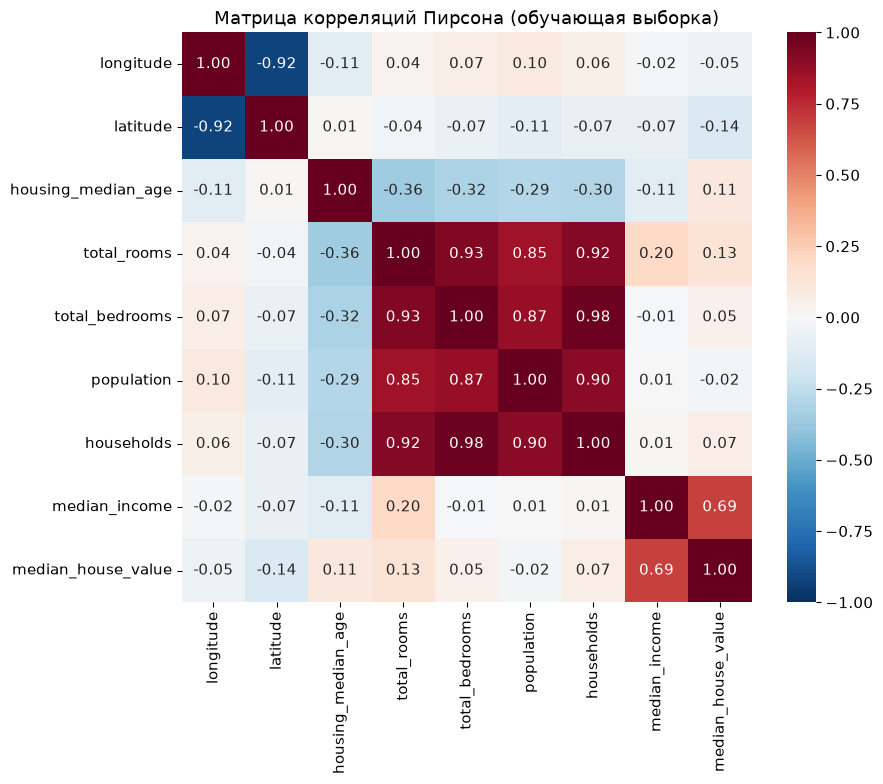

In [22]:
train_df = pd.concat([X_train[num_features], y_train], axis=1)
corr = train_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(9.2, 7.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
ax.grid(False)
ax.set_title('Матрица корреляций Пирсона (обучающая выборка)')
plt.show()

Матрицу корреляций Пирсона построили по обучающей выборке для восьми числовых признаков и цели, категориальный признак в неё не входит. Видны два блока сильно связанных признаков: total_rooms, total_bedrooms, population и households с r от 0,85 до 0,98, а также longitude и latitude с r = -0,92. С ценой заметно связан только median_income (r = 0,69), у остальных признаков |r| с ценой не больше 0,14.

In [23]:
corr_s = train_df.corr(method='spearman')
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = pd.DataFrame({'Пирсон': corr.where(mask).stack(),
                      'Спирмен': corr_s.where(mask).stack()}).dropna()
pairs = pairs.loc[pairs['Пирсон'].abs().sort_values(ascending=False).index]
display(pairs.head(10).round(3))
print('Наибольшее расхождение коэффициентов Пирсона и Спирмена:', round((corr - corr_s).abs().max().max(), 3))

Пирсон  Спирмен
total_bedrooms     households           0.979    0.976
total_rooms        total_bedrooms       0.929    0.915
longitude          latitude            -0.925   -0.878
total_rooms        households           0.917    0.906
population         households           0.902    0.902
total_bedrooms     population           0.871    0.869
total_rooms        population           0.851    0.815
median_income      median_house_value   0.686    0.673
housing_median_age total_rooms         -0.359   -0.356
                   total_bedrooms      -0.319   -0.308

Наибольшее расхождение коэффициентов Пирсона и Спирмена: 0.074


Основной метод - корреляция Пирсона, то есть линейная связь. Для проверки посчитали ещё коэффициент Спирмена: он даёт те же сильные пары, наибольшее расхождение 0,074 и на выводы не влияет. Самые сильные пары: total_bedrooms и households (0,979), total_rooms и total_bedrooms (0,929), longitude и latitude (-0,925), total_rooms и households (0,917), population и households (0,902). Четыре размерных признака растут вместе.

,r с ценой
median_income,0.686
latitude,-0.141
total_rooms,0.134
housing_median_age,0.107
households,0.067
total_bedrooms,0.052
longitude,-0.048
population,-0.024


Районов с доходом выше 10: 241, доля среди них районов с ценой 500 001: 85.1 %


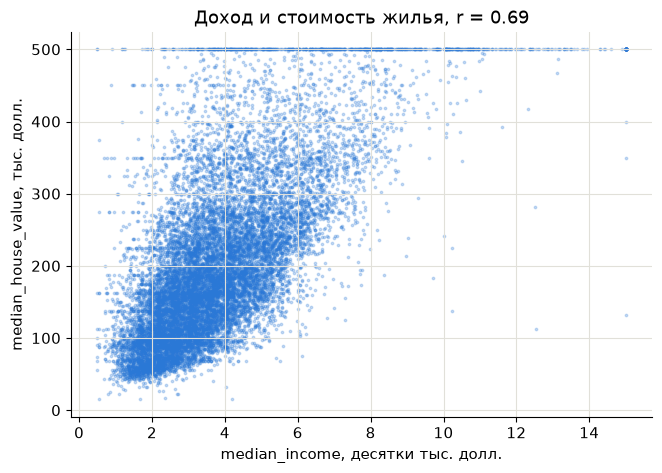

In [24]:
target_corr = corr[TARGET].drop(TARGET)
display(target_corr.loc[target_corr.abs().sort_values(ascending=False).index].round(3).to_frame('r с ценой'))
rich = X_train['median_income'] > 10
print(f'Районов с доходом выше 10: {rich.sum()}, доля среди них районов с ценой 500 001: '
      f'{(y_train[rich] == 500_001).mean() * 100:.1f} %')

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(X_train['median_income'], y_train / 1000, s=3, alpha=0.25, color=BLUE)
ax.set_xlabel('median_income, десятки тыс. долл.')
ax.set_ylabel('median_house_value, тыс. долл.')
ax.set_title(f'Доход и стоимость жилья, r = {corr.loc["median_income", TARGET]:.2f}')
plt.show()

Доход median_income и цена связаны с r = 0,686: с ростом дохода цена в среднем растёт, хотя разброс большой. Остальные связи слабые: latitude -0,141, total_rooms 0,134, housing_median_age 0,107, у остальных |r| < 0,07. Слабая парная корреляция не значит, что признак бесполезен: координаты почти не связаны с ценой, но на карте влияние местоположения видно. На диаграмме есть горизонтальная линия на уровне 500 тыс. долл., это срез цены. Районов с доходом выше 10 всего 241, и у 85,1 % из них цена 500 001, поэтому при высоком доходе линейный рост цены обрывается.

### 4.2. Коэффициенты VIF


In [25]:
def vif_table(data):
    exog = add_constant(data)
    values = [variance_inflation_factor(exog.values, i) for i in range(1, exog.shape[1])]
    return pd.Series(values, index=data.columns)

vif = pd.DataFrame({'VIF (числовые признаки)': vif_table(X_train_prep[num_features]),
                    'VIF (все признаки модели)': vif_table(X_train_prep)})
display(vif.round(2))

,VIF (числовые признаки),VIF (все признаки модели)
households,33.73,33.77
housing_median_age,1.26,1.32
latitude,8.82,20.01
longitude,8.73,18.16
median_income,1.71,1.77
ocean_proximity_INLAND,NaN,2.86
ocean_proximity_ISLAND,NaN,1.00
ocean_proximity_NEAR BAY,NaN,1.58
ocean_proximity_NEAR OCEAN,NaN,1.20
population,6.02,6.09


VIF признака равен 1 / (1 - R²), где R² - коэффициент детерминации регрессии этого признака на все остальные. В variance_inflation_factor передали матрицу train с добавленной константой (add_constant). Стандартизация VIF не меняет, поэтому взяли X_train_prep.

VIF числовых признаков получился такой: total_bedrooms 35,00, households 33,73, total_rooms 12,39, latitude 8,82, longitude 8,73, population 6,02, median_income 1,71 и housing_median_age 1,26.

Берём пороги 5 и 10. У total_bedrooms, households и total_rooms VIF выше 10, то есть мультиколлинеарность серьёзная. У latitude, longitude и population он между 5 и 10, и она заметная. У median_income и housing_median_age VIF ниже 5, мультиколлинеарности нет. VIF = 35 у total_bedrooms значит, что 97 % его дисперсии объясняется другими признаками (1 - 1/35), а дисперсия оценки его коэффициента в 35 раз больше, чем при некоррелированных признаках. Во втором столбце таблицы VIF по всем 12 признакам модели: с фиктивными признаками VIF у latitude и longitude вырастает до 20,01 и 18,16, потому что категории близости к океану тоже описывают местоположение.

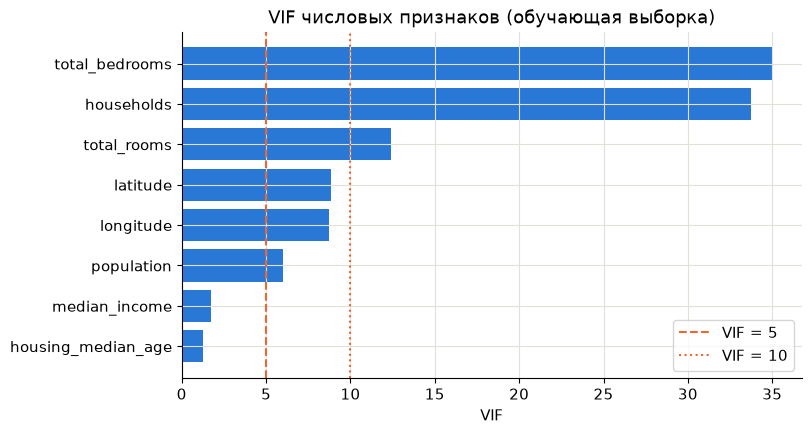

In [26]:
vif_num = vif['VIF (числовые признаки)'].dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(vif_num.index, vif_num.values, color=BLUE)
ax.axvline(5, color=ORANGE, ls='--', label='VIF = 5')
ax.axvline(10, color=ORANGE, ls=':', label='VIF = 10')
ax.set_xlabel('VIF')
ax.set_title('VIF числовых признаков (обучающая выборка)')
ax.legend()
plt.show()

На диаграмме показаны VIF числовых признаков по возрастанию, вертикальные линии - пороги 5 и 10. За порог 10 выходят total_bedrooms, households и total_rooms, между 5 и 10 лежат longitude, latitude и population, ниже 5 остаются median_income и housing_median_age.

In [27]:
reduced = [col for col in num_features if col not in ('total_bedrooms', 'households')]
vif_reduced = vif_table(X_train_prep[reduced])
display(vif_reduced.round(2).to_frame('VIF без total_bedrooms и households'))

,VIF без total_bedrooms и households
longitude,8.21
latitude,8.30
housing_median_age,1.26
total_rooms,4.50
population,4.26
median_income,1.29


Признаки total_bedrooms и households почти линейно выражаются через другие размерные признаки: корреляция между ними 0,979, а VIF 35,00 и 33,73. Их можно удалить или заменить относительными показателями (комнат и жителей на домохозяйство). Проверка показала, что без этих двух признаков VIF остальных ниже 10: у total_rooms 4,50, у population 4,26. У longitude и latitude остаётся 8,21 и 8,30, ведь одна их корреляция (-0,925) даёт VIF не меньше 1 / (1 - r²) ≈ 6,9. Удалять одну из координат нельзя, так как только вместе они задают положение района. Поэтому мультиколлинеарность устраняем методом главных компонент в разделе 4.5. Гребневая и лассо ослабляют её влияние штрафом на коэффициенты, так что модели раздела 4.3 строим на всех признаках.

### 4.3. Регрессия на исходных признаках
#### 4.3.1. Схема проверки и сетка alpha


In [28]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-2, 5, 29)
print('Проверяемые значения alpha:')
print(alphas.round(3))

Проверяемые значения alpha:
[1.0000000e-02 1.8000000e-02 3.2000000e-02 5.6000000e-02 1.0000000e-01
 1.7800000e-01 3.1600000e-01 5.6200000e-01 1.0000000e+00 1.7780000e+00
 3.1620000e+00 5.6230000e+00 1.0000000e+01 1.7783000e+01 3.1623000e+01
 5.6234000e+01 1.0000000e+02 1.7782800e+02 3.1622800e+02 5.6234100e+02
 1.0000000e+03 1.7782790e+03 3.1622780e+03 5.6234130e+03 1.0000000e+04
 1.7782794e+04 3.1622777e+04 5.6234133e+04 1.0000000e+05]


Для подбора alpha и оценки моделей использовали 5-кратную кросс-валидацию KFold(n_splits=5, shuffle=True, random_state=42). Обучающая выборка делится на 5 частей (фолдов), и модель 5 раз обучается на четырёх частях и проверяется на пятой. Параметр shuffle=True перемешивает строки перед делением, а random_state делает деление воспроизводимым. Сетка np.logspace(-2, 5, 29) содержит 29 значений alpha от 0,01 до 100 000, равномерно расположенных на логарифмической шкале: каждое следующее больше предыдущего примерно в 1,78 раза. Так проверяются и почти нулевой, и очень сильный штраф.

#### 4.3.2. Обучение моделей


In [29]:
pipe_lin = Pipeline([('prep', make_preprocessor()), ('model', LinearRegression())])
pipe_lin.fit(X_train, y_train)
pipe_lin

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['ocean_proximity'])],
                                   verbose_feature_names_out=False)),
              

Линейную регрессию собрали в Pipeline из двух шагов: prep (ColumnTransformer со стандартизацией числовых признаков и one-hot для ocean_proximity) и model (LinearRegression, коэффициенты находятся методом наименьших квадратов). Метод fit конвейера сначала обучает предобработку на X_train и преобразует его, потом обучает модель на преобразованных данных. Метод predict применяет к новым данным обученную предобработку (только transform) и модель. Благодаря конвейеру при кросс-валидации предобработка каждый раз обучается только на обучающих фолдах.

In [30]:
grid_lasso = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('model', Lasso())]),
                          param_grid={'model__alpha': alphas}, cv=cv,
                          scoring='neg_root_mean_squared_error')
grid_lasso.fit(X_train, y_train)
print('Лассо: лучшее alpha =', grid_lasso.best_params_['model__alpha'],
      f'; RMSE на кросс-валидации = {-grid_lasso.best_score_:.1f}')
print('Итераций координатного спуска до сходимости:', grid_lasso.best_estimator_.named_steps['model'].n_iter_)

Лассо: лучшее alpha = 0.01 ; RMSE на кросс-валидации = 68976.4
Итераций координатного спуска до сходимости: 405


Лассо-регрессия (Lasso) добавляет к ошибке L1-штраф alpha · сумма |w_j|. GridSearchCV перебирает 29 значений alpha (model__alpha - параметр alpha шага model), для каждого делает 5-кратную кросс-валидацию и выбирает значение с наименьшей средней RMSE (scoring='neg_root_mean_squared_error'). В scikit-learn ошибки берутся со знаком минус, чтобы большее значение означало лучшую модель. Потом модель с лучшим alpha переобучается на всей обучающей выборке (refit=True). Лучшее alpha получилось 0,01, то есть наименьшее значение сетки, а RMSE на кросс-валидации 68 976,4 долл. Штрафа почти нет. Координатный спуск сошёлся за 405 итераций, так что предел max_iter=1000 не мешал.

In [31]:
grid_ridge = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('model', Ridge())]),
                          param_grid={'model__alpha': alphas}, cv=cv,
                          scoring='neg_root_mean_squared_error')
grid_ridge.fit(X_train, y_train)
print('Гребневая: лучшее alpha =', grid_ridge.best_params_['model__alpha'],
      f'; RMSE на кросс-валидации = {-grid_ridge.best_score_:.1f}')

Гребневая: лучшее alpha = 31.622776601683793 ; RMSE на кросс-валидации = 68969.9


Гребневая регрессия (Ridge) добавляет L2-штраф alpha · сумма w_j². Сетка и фолды те же. Лучшее alpha равно 31,62, RMSE 68 969,9 долл., это на 6,5 долл. меньше, чем у лассо, то есть практически одно и то же.

In [32]:
models = {'Линейная': pipe_lin, 'Лассо': grid_lasso.best_estimator_, 'Гребневая': grid_ridge.best_estimator_}
for name, model in models.items():
    print(name, model.named_steps['model'].get_params())

Линейная {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
Лассо {'alpha': np.float64(0.01), 'copy_X': True, 'fit_intercept': True, 'max_iter': 1000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
Гребневая {'alpha': np.float64(31.622776601683793), 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}


Явно задавали у моделей только alpha лассо и гребневой, оно подобрано по сетке, остальное оставили по умолчанию: fit_intercept=True (свободный член оценивается) и positive=False (коэффициенты любого знака). У лассо max_iter=1000, selection='cyclic', tol=0.0001, у гребневой solver='auto'. У LinearRegression параметра регуляризации нет.

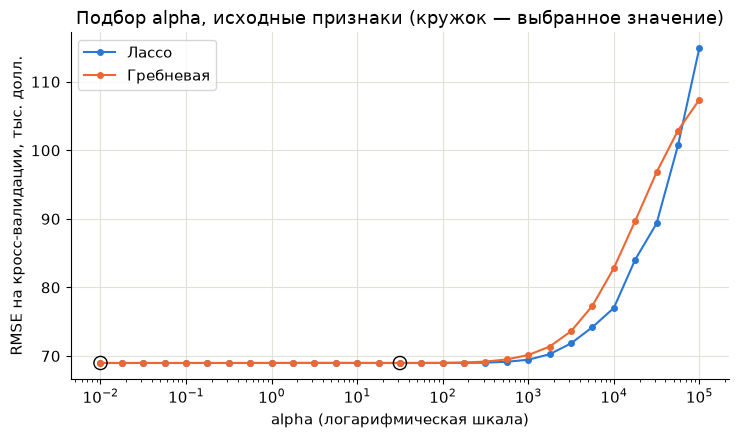

In [33]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for grid, name, color in [(grid_lasso, 'Лассо', BLUE), (grid_ridge, 'Гребневая', ORANGE)]:
    ax.plot(alphas, -grid.cv_results_['mean_test_score'] / 1000, marker='o', markersize=4,
            color=color, label=name)
    ax.scatter(grid.best_params_['model__alpha'], -grid.best_score_ / 1000, s=90,
               facecolor='none', edgecolor='black', zorder=3)
ax.set_xscale('log')
ax.set_xlabel('alpha (логарифмическая шкала)')
ax.set_ylabel('RMSE на кросс-валидации, тыс. долл.')
ax.set_title('Подбор alpha, исходные признаки (кружок — выбранное значение)')
ax.legend()
plt.show()

Кривые RMSE(alpha) обеих моделей почти горизонтальны при alpha от 0,01 до 100, там RMSE от 68 970 до 68 990 долл. При больших alpha RMSE быстро растёт: при alpha = 1 000 у лассо 69 451, у гребневой 70 135 долл., а при alpha = 100 000 у лассо 114 921, у гребневой 107 394 долл. Сильный штраф стягивает коэффициенты к нулю, и модель недообучается. Выигрыша от штрафа нет: выбранные alpha отличаются от соседних на единицы долларов, а разброс RMSE между фолдами около 1 940 долл. Это неудивительно, ведь здесь 16 344 наблюдения на 12 признаков.

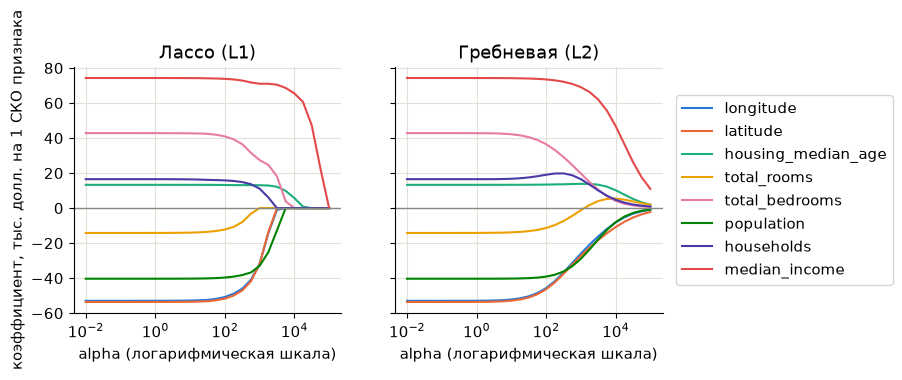

alpha = 0.01: ненулевых коэффициентов лассо 12 из 12, обнулены: []
alpha = 0.1: ненулевых коэффициентов лассо 12 из 12, обнулены: []
alpha = 1: ненулевых коэффициентов лассо 12 из 12, обнулены: []
alpha = 10: ненулевых коэффициентов лассо 12 из 12, обнулены: []
alpha = 100: ненулевых коэффициентов лассо 11 из 12, обнулены: ['ocean_proximity_ISLAND']
alpha = 1000: ненулевых коэффициентов лассо 9 из 12, обнулены: ['total_rooms', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY']
alpha = 10000: ненулевых коэффициентов лассо 3 из 12, обнулены: ['longitude', 'latitude', 'total_rooms', 'total_bedrooms', 'population', 'households', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
alpha = 100000: ненулевых коэффициентов лассо 0 из 12, обнулены: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_pr

In [34]:
COLORS8 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
path_lasso = pd.DataFrame([Lasso(alpha=a).fit(X_train_prep, y_train).coef_ for a in alphas],
                          index=alphas, columns=X_train_prep.columns)
path_ridge = pd.DataFrame([Ridge(alpha=a).fit(X_train_prep, y_train).coef_ for a in alphas],
                          index=alphas, columns=X_train_prep.columns)

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.2), sharey=True)
for ax, path, title in [(axes[0], path_lasso, 'Лассо (L1)'), (axes[1], path_ridge, 'Гребневая (L2)')]:
    for col, color in zip(num_features, COLORS8):
        ax.plot(path.index, path[col] / 1000, color=color, label=col)
    ax.axhline(0, color=GRAY, lw=1)
    ax.set_xscale('log')
    ax.set_xlabel('alpha (логарифмическая шкала)')
    ax.set_title(title)
axes[0].set_ylabel('коэффициент, тыс. долл. на 1 СКО признака')
axes[1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.show()
rows = []
for a in alphas[::4]:
    zero = [col for col in X_train_prep.columns if path_lasso.loc[a, col] == 0]
    print(f'alpha = {a:g}: ненулевых коэффициентов лассо {12 - len(zero)} из 12, обнулены: {zero}')
    rows.append({'alpha': a, 'ненулевых': 12 - len(zero), 'обнулены': ', '.join(zero)})

Пути коэффициентов показывают, как штраф меняет модель. У лассо (L1) коэффициенты по очереди становятся точно нулевыми: при alpha ≤ 10 ненулевые все 12, при alpha = 100 обнуляется ocean_proximity_ISLAND, при alpha = 1 000 ещё total_rooms и ocean_proximity_NEAR BAY (остаётся 9), при alpha = 10 000 остаются 3 коэффициента (median_income, housing_median_age, ocean_proximity_INLAND), а при alpha = 100 000 ни одного. У гребневой (L2) коэффициенты плавно уменьшаются, но нулевыми не становятся. Получается, что лассо отбирает признаки, а гребневая только сжимает. При выбранных alpha (0,01 и 31,6) штраф слабый, и коэффициенты почти как у обычной регрессии (раздел 4.3.4).

#### 4.3.3. Кросс-валидация


In [35]:
scoring = {'rmse': 'neg_root_mean_squared_error', 'r2': 'r2', 'mape': 'neg_mean_absolute_percentage_error'}

def cv_table(models):
    rows = {}
    for name, model in models.items():
        s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
        rows[name] = {'RMSE': -s['test_rmse'].mean(), 'RMSE ±': s['test_rmse'].std(),
                      'R2': s['test_r2'].mean(), 'R2 ±': s['test_r2'].std(),
                      'MAPE, %': -s['test_mape'].mean() * 100, 'MAPE ±, %': s['test_mape'].std() * 100}
    return pd.DataFrame(rows).T

cv_base = cv_table(models)
display(cv_base.round(4))

,RMSE,RMSE ±,R2,R2 ±,"MAPE, %","MAPE ±, %"
Линейная,68976.3340,1941.3818,0.6398,0.0103,28.7366,0.6933
Лассо,68976.3746,1941.4195,0.6398,0.0103,28.7366,0.6933
Гребневая,68969.9315,1952.3268,0.6399,0.0103,28.6883,0.7035


Функция cross_validate для каждой модели делает те же 5 фолдов и считает RMSE, R² и MAPE. MAPE перевели в проценты умножением на 100. В таблице указаны среднее по фолдам и стандартное отклонение (±). У всех моделей RMSE около 68 970-68 976 долл. (± около 1 940), R² около 0,640 (± 0,010), MAPE около 28,7 % (± 0,7). Разница между моделями не больше 6,4 долл. по RMSE, это примерно в 300 раз меньше разброса между фолдами. Оценки лассо и гребневой чуть оптимистичны, потому что alpha выбирали на тех же фолдах, а независимую оценку даст тестовая выборка.

#### 4.3.4. Коэффициенты моделей


In [36]:
coef = pd.DataFrame({name: model.named_steps['model'].coef_ for name, model in models.items()},
                    index=X_train_prep.columns)
coef.loc['свободный член'] = [model.named_steps['model'].intercept_ for model in models.values()]
display(coef.round(1))

feature_std = pipe_lin.named_steps['prep'].named_transformers_['num'].scale_
per_unit = pd.Series(pipe_lin.named_steps['model'].coef_[:len(num_features)] / feature_std, index=num_features)
display(per_unit.round(2).to_frame('линейная: долл. на 1 единицу признака'))

,Линейная,Лассо,Гребневая
longitude,-52949.9,-52949.8,-50389.2
latitude,-53627.6,-53627.4,-51073.6
housing_median_age,13285.4,13285.4,13348.6
total_rooms,-14205.2,-14205.0,-13176.5
total_bedrooms,42827.3,42827.2,40550.5
population,-40332.9,-40332.8,-40006.4
households,16530.8,16530.6,17516.7
median_income,74302.7,74302.6,74005.2
ocean_proximity_INLAND,-39119.8,-39119.9,-40361.3
ocean_proximity_ISLAND,137798.5,137757.7,15623.7


,линейная: долл. на 1 единицу признака
longitude,-26388.81
latitude,-25085.49
housing_median_age,1053.32
total_rooms,-6.55
total_bedrooms,101.55
population,-35.48
households,43.25
median_income,39192.19


Коэффициенты получены на стандартизованных признаках, поэтому их можно сравнивать между собой: это изменение прогноза в долларах при росте признака на 1 СКО. Для фиктивных признаков это разница с базовой категорией <1H OCEAN. Больше всех по модулю у median_income: +74 303 долл. на 1 СКО, дальше идут latitude (-53 628), longitude (-52 950), total_bedrooms (+42 827) и population (-40 333). Район INLAND при прочих равных дешевле базовых на 39 120 долл., а свободный член 218 687 долл. - прогноз для района со средними числовыми признаками и категорией <1H OCEAN. У сильно коррелированных признаков знаки противоположные: total_bedrooms +42 827, total_rooms -14 205, households +16 531, population -40 333. Это мультиколлинеарность, и такие коэффициенты по отдельности интерпретировать нельзя.

Коэффициенты лассо почти совпадают с линейной регрессией, заметнее всего ISLAND: 137 757,7 против 137 798,5. У гребневой коэффициенты немного сжаты: ISLAND уменьшен со 137 799 до 15 624 долл. В этом столбце всего 4 единицы, поэтому штраф alpha = 31,6 сжимает его сильнее всего (примерно в 9 раз). Во второй таблице коэффициенты в исходных единицах (коэффициент / СКО признака): у median_income +39 192 долл. на 1 единицу, у housing_median_age +1 053 долл. на год.

#### 4.3.5. Прогнозы и метрики на обучающей и тестовой выборках


In [37]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'RMSE': np.sqrt(mse),
            'R2': r2_score(y_true, y_pred),
            'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100,
            'MAE': mean_absolute_error(y_true, y_pred)}

rows = []
for name, model in models.items():
    for sample, X_s, y_s in [('train', X_train, y_train), ('test', X_test, y_test)]:
        y_pred = model.predict(X_s)
        rows.append({'модель': name, 'выборка': sample, **regression_metrics(y_s, y_pred)})
metrics_base = pd.DataFrame(rows).set_index(['модель', 'выборка'])
display(metrics_base.round(4))

RMSE      R2  MAPE, %         MAE
модель    выборка                                         
Линейная  train    68734.1634  0.6424  28.6625  49741.9031
          test     68157.3296  0.6630  28.1829  49481.7845
Лассо     train    68734.1634  0.6424  28.6625  49741.9065
          test     68157.3443  0.6630  28.1829  49481.7974
Гребневая train    68765.6899  0.6420  28.6347  49754.9829
          test     68253.4120  0.6621  28.1614  49514.3866

Прогнозы для train и test получили методом predict конвейера, а метрики считает функция regression_metrics. RMSE - корень из MSE, в долларах, как и MAE, MAPE умножена на 100 и выводится в процентах, а R² безразмерный.

Итоговые метрики на test у линейной регрессии такие: RMSE = 68 157 долл., R² = 0,663, MAPE = 28,18 %, MAE = 49 482 долл. У лассо значения те же, а у гребневой RMSE = 68 253 долл., R² = 0,662, MAPE = 28,16 %, MAE = 49 514 долл.

Модель объясняет около 66 % дисперсии цены, а MAE около 49,5 тыс. долл. при средней цене 207 тыс. Переобучения нет: на train метрики почти такие же (у линейной RMSE 68 734, R² 0,642). Ошибка на test даже немного меньше, это объясняется конкретным разбиением (см. ниже). MAPE около 28 %, то есть ошибка заметная на обеих выборках, и это похоже на недообучение: линейная модель слишком проста.

In [38]:
print('Минимальная цена:', y.min(), 'долл.; районов дешевле 50 000 долл.:', (y < 50_000).sum())
ape = (y_test - pipe_lin.predict(X_test)).abs() / y_test * 100
mape_groups = ape.groupby(pd.qcut(y_test, 5), observed=True).mean()
display(mape_groups.round(1).to_frame('MAPE линейной модели на test, %'))

Минимальная цена: 14999.0 долл.; районов дешевле 50 000 долл.: 195


,"MAPE линейной модели на test, %"
median_house_value,
"(14998.999, 106300.0]",49.1
"(106300.0, 156000.0]",31.9
"(156000.0, 209400.0]",22.9
"(209400.0, 296100.0]",14.7
"(296100.0, 500001.0]",22.2


Нулевых и близких к нулю значений цены нет: минимум 14 999 долл., а дешевле 50 000 долл. всего 195 районов, поэтому MAPE определена. MAPE относительная, так что одна и та же ошибка в долларах у дешёвого района даёт больший процент. Тестовые районы разбили на 5 равных по численности групп по цене: у самой дешёвой (до 106 300 долл.) MAPE = 49,1 %, у четвёртой 14,7 %, у самой дорогой 22,2 %. Общая MAPE около 28 % сильно зависит от дешёвых районов, поэтому модели надо оценивать вместе с RMSE и MAE.

In [39]:
rows = []
for seed in [0, 1, 7, 42, 123]:
    X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.2, random_state=seed)
    model = Pipeline([('prep', make_preprocessor()), ('model', LinearRegression())]).fit(X_a, y_a)
    rows.append({'random_state': seed, **regression_metrics(y_b, model.predict(X_b))})
seeds = pd.DataFrame(rows).set_index('random_state')
display(seeds.round(4))

,RMSE,R2,"MAPE, %",MAE
random_state,,,,
0,68675.1209,0.6483,28.3577,49443.8039
1,68679.0056,0.6490,28.6877,49977.9894
7,68795.7312,0.6447,29.3688,50113.5681
42,68157.3296,0.6630,28.1829,49481.7845
123,69056.8538,0.6341,28.2023,49746.4190


Линейную модель обучили на пяти разбиениях с разным random_state. Тестовая RMSE получилась от 68 157 (наше разбиение, 42) до 69 057 долл. (123), R² от 0,634 до 0,663, MAPE от 28,18 до 29,37 %. Наше разбиение дало лучший результат из пяти, а при остальных RMSE от 68 675 до 69 057 долл., что близко к train (68 734) или больше. Значит, ошибка на test меньше, чем на train, только из-за конкретного разбиения. Разброс RMSE около 900 долл. (1,3 %), это намного меньше разницы между моделями до и после PCA (раздел 4.6).

In [40]:
best = cv_base['RMSE'].idxmin()
tolerance = cv_base.loc[best, 'RMSE ±']
equivalent = [name for name in cv_base.index if cv_base.loc[name, 'RMSE'] <= cv_base.loc[best, 'RMSE'] + tolerance]
print('Минимальная RMSE на кросс-валидации:', best)
print('Модели в пределах одного стандартного отклонения от неё:', equivalent)
print('Выбрана самая простая из равноценных:', equivalent[0])

Минимальная RMSE на кросс-валидации: Гребневая
Модели в пределах одного стандартного отклонения от неё: ['Линейная', 'Лассо', 'Гребневая']
Выбрана самая простая из равноценных: Линейная


Основная метрика - RMSE на кросс-валидации, по ней подбирали alpha. Она в долларах и сильнее штрафует крупные ошибки. R² на одной выборке упорядочивает модели так же, как RMSE, а MAPE дополнительная, и порядок по ней может быть другим. Если разница RMSE меньше стандартного отклонения RMSE по фолдам, модели равноценны, и из равноценных берём самую простую. Минимальная RMSE у гребневой, но все три модели в пределах одного СКО (1 952 долл.), поэтому выбрали линейную: у неё нет гиперпараметров. На test RMSE и R² лучше у линейной (68 157 против 68 253), а MAPE лучше у гребневой (28,16 % против 28,18 %). Разница мала, модели равноценны.

### 4.4. Анализ остатков


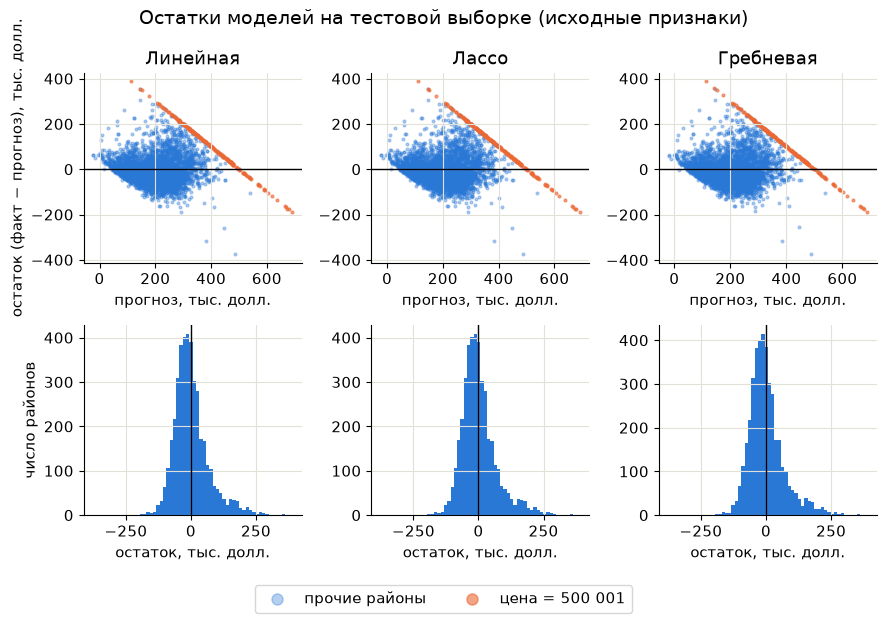

In [41]:
def plot_residuals(models, title):
    capped = (y_test == 500_001).to_numpy()
    fig, axes = plt.subplots(2, 3, figsize=(9, 5.8))
    for j, (name, model) in enumerate(models.items()):
        y_pred = model.predict(X_test)
        resid = (y_test - y_pred).to_numpy()
        axes[0, j].scatter(y_pred[~capped] / 1000, resid[~capped] / 1000, s=4, alpha=0.35,
                           color=BLUE, label='прочие районы')
        axes[0, j].scatter(y_pred[capped] / 1000, resid[capped] / 1000, s=4, alpha=0.6,
                           color=ORANGE, label='цена = 500 001')
        axes[0, j].axhline(0, color='black', lw=1)
        axes[0, j].set_title(name)
        axes[0, j].set_xlabel('прогноз, тыс. долл.')
        axes[1, j].hist(resid / 1000, bins=60, color=BLUE)
        axes[1, j].axvline(0, color='black', lw=1)
        axes[1, j].set_xlabel('остаток, тыс. долл.')
    axes[0, 0].set_ylabel('остаток (факт − прогноз), тыс. долл.')
    axes[1, 0].set_ylabel('число районов')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 0), ncol=2, markerscale=4)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()

plot_residuals(models, 'Остатки моделей на тестовой выборке (исходные признаки)')

На графиках остатков на тестовой выборке по горизонтали прогноз, по вертикали остаток e = y - прогноз. У трёх моделей картина одинаковая, потому что коэффициенты почти совпадают. С ростом прогноза облако расширяется в форме воронки, то есть дисперсия остатков непостоянна (гетероскедастичность). Оранжевые точки - районы с ценой 500 001, они лежат на наклонной прямой e = 500 001 - прогноз. Нижняя граница облака слева тоже прямая, ведь цена не ниже 14 999 долл. Гистограммы остатков вытянуты вправо: крупные положительные остатки у сильно недооценённых районов, среди которых много районов со срезанной ценой.

In [42]:
y_pred_lin = pipe_lin.predict(X_test)
resid_lin = y_test - y_pred_lin
spread = resid_lin.groupby(pd.qcut(y_pred_lin, 5), observed=True).std() / 1000
display(spread.round(1).to_frame('СКО остатков линейной модели, тыс. долл.'))
print('Отрицательных прогнозов на test:', (y_pred_lin < 0).sum(), '; минимальный прогноз:', round(y_pred_lin.min()))
print('Среднее остатков:', round(resid_lin.mean()), '; медиана:', round(resid_lin.median()))
print('Наибольший остаток:', round(resid_lin.max()), '; наименьший:', round(resid_lin.min()))

,"СКО остатков линейной модели, тыс. долл."
"(-21714.221, 126158.456]",42.5
"(126158.456, 179331.966]",51.9
"(179331.966, 224703.153]",67.2
"(224703.153, 276162.617]",78.8
"(276162.617, 690005.056]",83.8


Отрицательных прогнозов на test: 4 ; минимальный прогноз: -21714
Среднее остатков: 1573 ; медиана: -8644
Наибольший остаток: 388364 ; наименьший: -374538


Остатки посчитали в пяти равных по численности группах по прогнозу. СКО остатков растёт с 42,5 тыс. долл. до 83,8 тыс., то есть почти вдвое, что подтверждает воронку. Отрицательных прогнозов 4, минимальный -21 714 долл., так как линейная модель не ограничена снизу. Средний остаток на test 1 573 долл., близок к нулю, а медиана остатков -8 644 долл. Наибольший остаток +388 364, наименьший -374 538 долл.

In [43]:
def bp_table(models):
    rows = []
    for name, model in models.items():
        for sample, X_s, y_s in [('train', X_train, y_train), ('test', X_test, y_test)]:
            resid = y_s - model.predict(X_s)
            exog = add_constant(model.named_steps['prep'].transform(X_s))
            lm, lm_pvalue, f_stat, f_pvalue = het_breuschpagan(resid, exog)
            rows.append({'модель': name, 'выборка': sample, 'LM': lm, 'p-значение': lm_pvalue})
    return pd.DataFrame(rows).set_index(['модель', 'выборка'])

bp_base = bp_table(models)
shown = bp_base.copy()
shown['p-значение'] = shown['p-значение'].map('{:.1e}'.format)
display(shown.round(1))

LM p-значение
модель    выборка                  
Линейная  train    714.2   4.1e-145
          test     310.7    2.6e-59
Лассо     train    714.2   4.1e-145
          test     310.7    2.6e-59
Гребневая train    716.9   1.1e-145
          test     325.0    2.7e-62

В тесте Бреуша-Пагана нулевая гипотеза H0 говорит, что дисперсия остатков не зависит от признаков (гомоскедастичность). Квадраты остатков регрессируются на признаки модели, и статистика LM = n·R² этой регрессии при H0 имеет распределение хи-квадрат с 12 степенями свободы. У линейной модели LM = 714,2 на train и 310,7 на test, p-значения 4,1·10⁻¹⁴⁵ и 2,6·10⁻⁵⁹, гораздо меньше 0,05. Гипотеза о гомоскедастичности отвергается, и у лассо и гребневой то же самое, то есть остатки гетероскедастичны. Прогнозы строить можно, но точность неодинакова: у дорогих районов ошибка больше общей RMSE, у дешёвых меньше.

### 4.5. Метод главных компонент
#### 4.5.1. Стандартизация перед PCA


In [44]:
scaler_pca = StandardScaler().fit(X_train[num_features])
Z_train = scaler_pca.transform(X_train[num_features])
Z_test = scaler_pca.transform(X_test[num_features])
print('Средние Z_train:', Z_train.mean(axis=0).round(3))
print('СКО Z_train:   ', Z_train.std(axis=0).round(3))

Средние Z_train: [-0.  0. -0.  0. -0.  0. -0. -0.]
СКО Z_train:    [1. 1. 1. 1. 1. 1. 1. 1.]


Перед PCA стандартизовали восемь числовых признаков: StandardScaler обучили (fit) только на train, а потом применили transform с теми же параметрами к train и test. После этого у каждого признака среднее 0 и СКО 1. Без стандартизации PCA раскладывал бы ковариационную матрицу, и главными были бы признаки с наибольшей дисперсией (total_rooms, population). После стандартизации раскладывается корреляционная матрица. Категориальный признак в PCA не включаем, фиктивные признаки ocean_proximity идут в модель без изменений.

#### 4.5.2. Собственные значения и доли объяснённой дисперсии


In [45]:
pca_full = PCA().fit(Z_train)
eigenvalues = pca_full.explained_variance_
cum_share = np.cumsum(pca_full.explained_variance_ratio_) * 100
variance = pd.DataFrame({'собственное значение': eigenvalues,
                         'доля дисперсии, %': pca_full.explained_variance_ratio_ * 100,
                         'накопленная доля, %': cum_share},
                        index=[f'PC{i}' for i in range(1, len(eigenvalues) + 1)])
display(variance.round(3))
print('Сумма собственных значений:', round(eigenvalues.sum(), 4))

,собственное значение,"доля дисперсии, %","накопленная доля, %"
PC1,3.896,48.696,48.696
PC2,1.907,23.837,72.532
PC3,1.069,13.368,85.900
PC4,0.826,10.325,96.225
PC5,0.157,1.958,98.184
PC6,0.083,1.032,99.216
PC7,0.047,0.592,99.808
PC8,0.015,0.192,100.000


Сумма собственных значений: 8.0005


PCA обучили на стандартизованной train без ограничения числа компонент, получилось 8 собственных значений. Собственное значение - это дисперсия данных вдоль компоненты, доля объяснённой дисперсии равна λ / сумма всех λ (explained_variance_ratio_), а накопленная доля - сумма долей первых k компонент (np.cumsum). Сумма собственных значений 8,0005, то есть примерно 8, столько же, сколько стандартизованных признаков. Отличие в четвёртом знаке возникает потому, что PCA делит на n - 1, а StandardScaler на n. Доли первых компонент: PC1 48,70 %, PC2 23,84 %, PC3 13,37 %, PC4 10,33 %, вместе четыре компоненты дают 96,23 %. На последние четыре приходится менее 4 %.

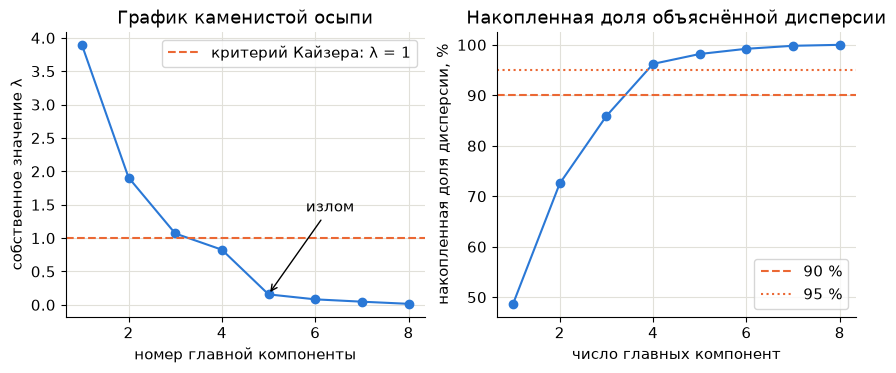

In [46]:
k_range = np.arange(1, len(eigenvalues) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.7))
axes[0].plot(k_range, eigenvalues, marker='o', color=BLUE)
axes[0].axhline(1, color=ORANGE, ls='--', label='критерий Кайзера: λ = 1')
axes[0].annotate('излом', xy=(5, eigenvalues[4]), xytext=(5.8, 1.4),
                 arrowprops={'arrowstyle': '->', 'color': 'black'})
axes[0].set_xlabel('номер главной компоненты')
axes[0].set_ylabel('собственное значение λ')
axes[0].set_title('График каменистой осыпи')
axes[0].legend()
axes[1].plot(k_range, cum_share, marker='o', color=BLUE)
axes[1].axhline(90, color=ORANGE, ls='--', label='90 %')
axes[1].axhline(95, color=ORANGE, ls=':', label='95 %')
axes[1].set_xlabel('число главных компонент')
axes[1].set_ylabel('накопленная доля дисперсии, %')
axes[1].set_title('Накопленная доля объяснённой дисперсии')
axes[1].legend(loc='lower right')
plt.show()

Слева график каменистой осыпи с собственными значениями по номерам компонент. На первых четырёх компонентах значение падает от 3,90 до 0,83, потом резко до 0,16 на пятой и дальше почти не меняется (0,08; 0,05; 0,02). Излом на пятой компоненте, поэтому оставляем четыре. Справа накопленная доля: порог 90 % впервые превышен при 4 компонентах (96,2 %), порог 95 % тоже при 4.

#### 4.5.3. Выбор числа компонент


In [47]:
criteria = pd.Series({
    'Кайзер: λ > 1': int((eigenvalues > 1).sum()),
    'Джоллифф: λ > 0,7': int((eigenvalues > 0.7).sum()),
    'накопленная доля ≥ 80 %': int(np.argmax(cum_share >= 80) + 1),
    'накопленная доля ≥ 90 %': int(np.argmax(cum_share >= 90) + 1),
    'накопленная доля ≥ 95 %': int(np.argmax(cum_share >= 95) + 1),
}, name='компонент')
display(criteria.to_frame())

loadings_full = pca_full.components_.T * np.sqrt(eigenvalues)
communality = pd.DataFrame({'3 компоненты': (loadings_full[:, :3] ** 2).sum(axis=1),
                            '4 компоненты': (loadings_full[:, :4] ** 2).sum(axis=1)}, index=num_features)
display(communality.round(3))

N_COMPONENTS = int(np.argmax(cum_share >= 90) + 1)
print('Выбрано главных компонент:', N_COMPONENTS)

,компонент
Кайзер: λ > 1,3
"Джоллифф: λ > 0,7",4
накопленная доля ≥ 80 %,3
накопленная доля ≥ 90 %,4
накопленная доля ≥ 95 %,4


,3 компоненты,4 компоненты
longitude,0.965,0.968
latitude,0.960,0.969
housing_median_age,0.344,0.999
total_rooms,0.933,0.944
total_bedrooms,0.960,0.964
population,0.879,0.885
households,0.964,0.972
median_income,0.867,0.998


Выбрано главных компонент: 4


Число компонент выбираем по доле дисперсии и проверяем по осыпи и другим критериям. По критерию Кайзера (λ > 1) получается 3 компоненты, так как λ4 = 0,83 < 1. Порог 80 % даёт 3 компоненты (85,9 %), пороги 90 % и 95 % дают 4, а критерий Джоллиффа (λ > 0,7) тоже 4 компоненты. Выбор между 3 и 4 решает таблица общностей (сумма квадратов нагрузок): при 3 компонентах housing_median_age объясняется на 34,4 %, при 4 на 99,9 %, а median_income на 86,7 % и 99,8 %. Четвёртая компонента несёт почти всю информацию о возрасте домов. Поэтому выбрали 4 компоненты: это наименьшее число с накопленной долей не меньше 90 %, и оно совпадает с изломом на осыпи.

#### 4.5.4. Нагрузки главных компонент


,PC1,PC2,PC3,PC4
longitude,0.077,0.702,-0.049,-0.064
latitude,-0.074,-0.702,0.004,-0.104
housing_median_age,-0.218,-0.018,-0.385,0.890
total_rooms,0.484,-0.077,0.093,0.113
total_bedrooms,0.491,-0.060,-0.117,0.064
population,0.471,-0.027,-0.115,0.084
households,0.492,-0.063,-0.109,0.097
median_income,0.045,0.023,0.896,0.399


,PC1,PC2,PC3,PC4
longitude,0.151,0.969,-0.050,-0.059
latitude,-0.147,-0.969,0.005,-0.095
housing_median_age,-0.430,-0.025,-0.398,0.809
total_rooms,0.955,-0.107,0.096,0.103
total_bedrooms,0.969,-0.083,-0.121,0.058
population,0.929,-0.038,-0.119,0.076
households,0.971,-0.087,-0.112,0.088
median_income,0.088,0.032,0.926,0.362


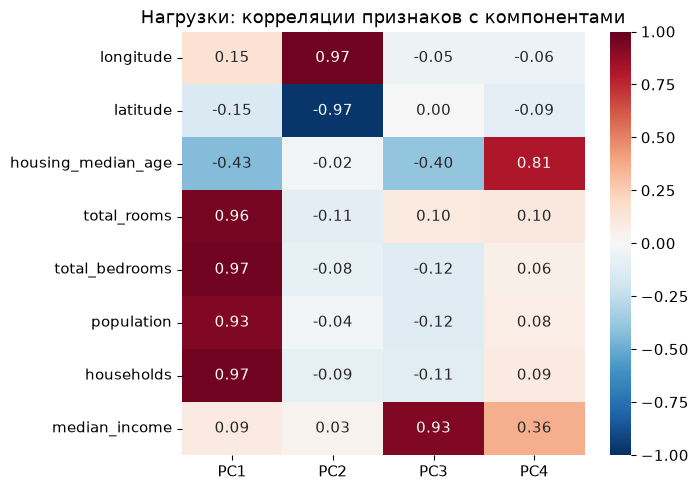

In [48]:
pca = PCA(n_components=N_COMPONENTS).fit(Z_train)
pc_names = [f'PC{i}' for i in range(1, N_COMPONENTS + 1)]
weights = pd.DataFrame(pca.components_.T, index=num_features, columns=pc_names)
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=num_features, columns=pc_names)
display(weights.round(3))
display(loadings.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.grid(False)
ax.set_title('Нагрузки: корреляции признаков с компонентами')
plt.show()

Первая таблица содержит веса компонент pca.components_ (собственные векторы), вторая таблица и тепловая карта - нагрузки, равные весу × √λ. Для стандартизованных данных нагрузки - это корреляции признаков с компонентами. Первая компонента PC1 (48,7 %) отвечает за размер района: высокие нагрузки у total_rooms (0,96), total_bedrooms (0,97), population (0,93) и households (0,97), а у housing_median_age нагрузка отрицательная (-0,43). PC2 (23,8 %) отвечает за местоположение: longitude 0,97 и latitude -0,97. PC3 (13,4 %) отвечает за доход: median_income 0,93, housing_median_age -0,40. PC4 (10,3 %) отвечает за возраст застройки: housing_median_age 0,81, median_income 0,36. Знак компоненты определён с точностью до умножения на -1.

#### 4.5.5. Преобразование выборок и размеры матриц


In [49]:
PC_train = pca.transform(Z_train)
PC_test = pca.transform(Z_test)
n_dummies = X_train_prep.shape[1] - len(num_features)
print('Числовые признаки до PCA:  train', Z_train.shape, ' test', Z_test.shape)
print('Главные компоненты:        train', PC_train.shape, ' test', PC_test.shape)
print('Вся матрица признаков модели: до PCA', X_train_prep.shape,
      ' после PCA', (PC_train.shape[0], PC_train.shape[1] + n_dummies))

Числовые признаки до PCA:  train (16344, 8)  test (4086, 8)
Главные компоненты:        train (16344, 4)  test (4086, 4)
Вся матрица признаков модели: до PCA (16344, 12)  после PCA (16344, 8)


Тестовую выборку перевели в компоненты без повторного обучения: сначала scaler_pca.transform (средние и СКО train), затем pca.transform (собственные векторы train). Числовая часть уменьшилась с 16 344 × 8 и 4 086 × 8 до 16 344 × 4 и 4 086 × 4, а вся матрица признаков с четырьмя фиктивными - с 12 до 8 столбцов.

#### 4.5.6. Проверка устранения мультиколлинеарности


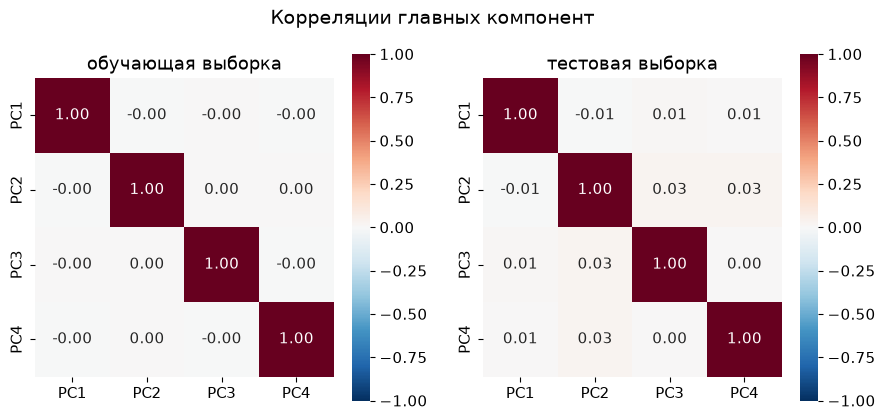

,VIF (компоненты),VIF (компоненты + dummy)
PC1,1.0,1.012
PC2,1.0,1.403
PC3,1.0,1.016
PC4,1.0,1.210
ocean_proximity_INLAND,NaN,1.496
ocean_proximity_ISLAND,NaN,1.001
ocean_proximity_NEAR BAY,NaN,1.550
ocean_proximity_NEAR OCEAN,NaN,1.132


Наибольшая по модулю корреляция компонент на test: 0.031


In [50]:
pc_train_df = pd.DataFrame(PC_train, columns=pc_names)
pc_test_df = pd.DataFrame(PC_test, columns=pc_names)
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.5))
for ax, data, title in [(axes[0], pc_train_df, 'обучающая выборка'), (axes[1], pc_test_df, 'тестовая выборка')]:
    sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax)
    ax.grid(False)
    ax.set_title(title)
fig.suptitle('Корреляции главных компонент', fontsize=14)
plt.show()

dummies = X_train_prep.drop(columns=num_features).reset_index(drop=True)
vif_pca = pd.DataFrame({'VIF (компоненты)': vif_table(pc_train_df),
                        'VIF (компоненты + dummy)': vif_table(pd.concat([pc_train_df, dummies], axis=1))})
display(vif_pca.round(3))
off_diag = pc_test_df.corr().where(~np.eye(N_COMPONENTS, dtype=bool)).abs().max().max()
print('Наибольшая по модулю корреляция компонент на test:', round(off_diag, 3))

На train корреляции между компонентами равны нулю, значения -0,00 - это округлённые нули, ведь компоненты ортогональны по построению. На test корреляции не строго нулевые, так как компоненты построены по train, наибольшая по модулю 0,031. VIF всех компонент равен 1,0 (у исходных признаков был до 35,00), а с фиктивными признаками VIF не больше 1,55. Мультиколлинеарность устранена.

### 4.6. Регрессия на главных компонентах
#### 4.6.1. Модели в Pipeline с PCA


In [51]:
def make_pca_preprocessor(n_components):
    num_pipe = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=n_components))])
    return ColumnTransformer([
        ('num', num_pipe, num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features),
    ], verbose_feature_names_out=False)

pipe_lin_pca = Pipeline([('prep', make_pca_preprocessor(N_COMPONENTS)), ('model', LinearRegression())])
pipe_lin_pca.fit(X_train, y_train)
pipe_lin_pca

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler()),
                                                                  ('pca',
                                                                   PCA(n_components=4))]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                      

Модели на компонентах собрали в такой же Pipeline, предобработка другая. Для числовых признаков стоит вложенный конвейер: StandardScaler, потом PCA(n_components=4), а для ocean_proximity тот же OneHotEncoder. Порядок такой: стандартизация (обязательна перед PCA), PCA, модель. Стандартизация и PCA находятся внутри конвейера, поэтому при кросс-валидации обучаются заново на обучающих фолдах, а к проверочному фолду только применяются.

In [52]:
grid_lasso_pca = GridSearchCV(Pipeline([('prep', make_pca_preprocessor(N_COMPONENTS)), ('model', Lasso())]),
                              param_grid={'model__alpha': alphas}, cv=cv,
                              scoring='neg_root_mean_squared_error').fit(X_train, y_train)
grid_ridge_pca = GridSearchCV(Pipeline([('prep', make_pca_preprocessor(N_COMPONENTS)), ('model', Ridge())]),
                              param_grid={'model__alpha': alphas}, cv=cv,
                              scoring='neg_root_mean_squared_error').fit(X_train, y_train)
for name, grid in [('Лассо', grid_lasso_pca), ('Гребневая', grid_ridge_pca)]:
    print(f'{name} на главных компонентах: лучшее alpha = {grid.best_params_["model__alpha"]}, '
          f'RMSE на кросс-валидации = {-grid.best_score_:.1f}')

Лассо на главных компонентах: лучшее alpha = 0.01, RMSE на кросс-валидации = 72781.6
Гребневая на главных компонентах: лучшее alpha = 0.01, RMSE на кросс-валидации = 72781.7


Alpha для лассо и гребневой на компонентах подбирали по той же сетке из 29 значений, фолды cv и метрика те же. У обеих лучшее alpha равно 0,01 (наименьшее), RMSE на кросс-валидации 72 781,6 и 72 781,7 долл. Регуляризация и здесь не помогает, ведь после PCA VIF примерно 1 и мультиколлинеарности уже нет.

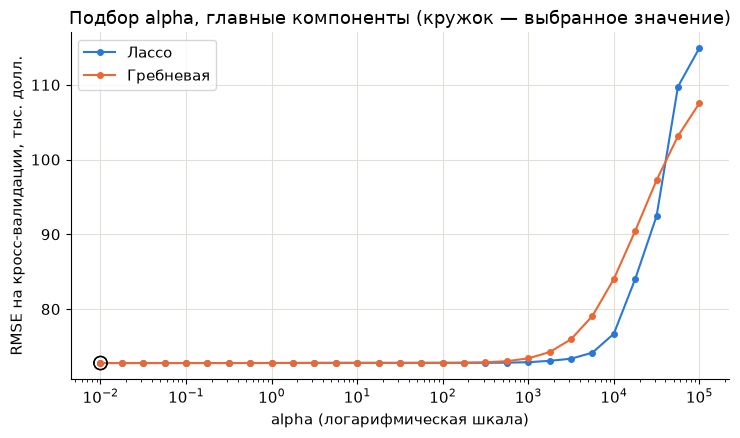

In [53]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for grid, name, color in [(grid_lasso_pca, 'Лассо', BLUE), (grid_ridge_pca, 'Гребневая', ORANGE)]:
    ax.plot(alphas, -grid.cv_results_['mean_test_score'] / 1000, marker='o', markersize=4,
            color=color, label=name)
    ax.scatter(grid.best_params_['model__alpha'], -grid.best_score_ / 1000, s=90,
               facecolor='none', edgecolor='black', zorder=3)
ax.set_xscale('log')
ax.set_xlabel('alpha (логарифмическая шкала)')
ax.set_ylabel('RMSE на кросс-валидации, тыс. долл.')
ax.set_title('Подбор alpha, главные компоненты (кружок — выбранное значение)')
ax.legend()
plt.show()

Кривые RMSE(alpha) на компонентах похожи на кривые раздела 4.3: почти горизонтальный участок при малых alpha и рост ошибки при больших. Весь график при этом выше: минимальная RMSE около 72,8 тыс. долл. против 69,0 тыс. на исходных признаках.

In [54]:
check = cross_validate(pipe_lin_pca, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error',
                       return_estimator=True)
rows = []
for i, est in enumerate(check['estimator'], 1):
    num_pipe = est.named_steps['prep'].named_transformers_['num']
    print(f'фолд {i}: среднее median_income в scaler = {num_pipe.named_steps["scaler"].mean_[-1]:.4f}, '
          f'доля дисперсии PC1 = {num_pipe.named_steps["pca"].explained_variance_ratio_[0]:.4f}')
    rows.append({'фолд': i, 'среднее median_income': num_pipe.named_steps['scaler'].mean_[-1],
                 'доля дисперсии PC1': num_pipe.named_steps['pca'].explained_variance_ratio_[0]})

фолд 1: среднее median_income в scaler = 3.8743, доля дисперсии PC1 = 0.4881
фолд 2: среднее median_income в scaler = 3.8661, доля дисперсии PC1 = 0.4882
фолд 3: среднее median_income в scaler = 3.8747, доля дисперсии PC1 = 0.4856
фолд 4: среднее median_income в scaler = 3.8707, доля дисперсии PC1 = 0.4875
фолд 5: среднее median_income в scaler = 3.8662, доля дисперсии PC1 = 0.4857


Проверили, что стандартизация и PCA обучаются заново в каждом разбиении. Вызов cross_validate(..., return_estimator=True) возвращает пять обученных конвейеров. Среднее median_income в scaler по фолдам разное, от 3,8661 до 3,8747, и доля дисперсии PC1 тоже, от 0,4856 до 0,4882. Значит, каждый фолд использует свои параметры, посчитанные без проверочной части.

In [55]:
models_pca = {'Линейная': pipe_lin_pca, 'Лассо': grid_lasso_pca.best_estimator_,
              'Гребневая': grid_ridge_pca.best_estimator_}
cv_pca = cv_table(models_pca)
display(cv_pca.round(4))

,RMSE,RMSE ±,R2,R2 ±,"MAPE, %","MAPE ±, %"
Линейная,72781.6057,1608.6926,0.5989,0.0063,29.9543,0.751
Лассо,72781.6442,1608.7506,0.5989,0.0063,29.9544,0.751
Гребневая,72781.7460,1609.0354,0.5989,0.0063,29.9544,0.751


Кросс-валидация на компонентах дала RMSE = 72 782 ± 1 609 долл., R² = 0,599 ± 0,006 и MAPE = 29,95 ± 0,75 %, у трёх моделей одинаково. По сравнению с исходными признаками RMSE выросла на 3 805 долл. (5,5 %), а R² снизился с 0,640 до 0,599.

In [56]:
coef_pca = pd.DataFrame({name: model.named_steps['model'].coef_ for name, model in models_pca.items()},
                        index=pipe_lin_pca.named_steps['prep'].get_feature_names_out())
coef_pca.loc['свободный член'] = [model.named_steps['model'].intercept_ for model in models_pca.values()]
display(coef_pca.round(1))

,Линейная,Лассо,Гребневая
pca0,3755.3,3755.3,3755.3
pca1,-1083.6,-1083.6,-1083.5
pca2,58824.9,58824.9,58824.8
pca3,42585.3,42585.4,42585.4
ocean_proximity_INLAND,-71480.3,-71480.3,-71480.2
ocean_proximity_ISLAND,168402.5,168361.6,167982.2
ocean_proximity_NEAR BAY,5436.1,5435.9,5436.0
ocean_proximity_NEAR OCEAN,16453.0,16452.9,16452.8
свободный член,226405.3,226405.4,226405.5


Коэффициенты pca0-pca3 относятся к PC1-PC4 (долл. на единицу компоненты). Наибольшие у PC3 (доход) +58 825 и PC4 (возраст застройки) +42 585, а у PC1 (размер района) и PC2 (местоположение) малые: +3 755 и -1 084. Коэффициент INLAND вырос по модулю до -71 480 долл. против -39 120 до PCA, причину смотрим в разделе 4.6.2. Коэффициенты трёх моделей практически совпадают.

#### 4.6.2. Сравнение моделей до и после PCA


In [57]:
rows = []
for stage, model_set, cv_res in [('до PCA', models, cv_base), ('после PCA', models_pca, cv_pca)]:
    for name, model in model_set.items():
        rows.append({'модель': name, 'признаки': stage, **regression_metrics(y_test, model.predict(X_test)),
                     'RMSE CV': cv_res.loc[name, 'RMSE']})
comparison = pd.DataFrame(rows).set_index(['модель', 'признаки'])
display(comparison.round(4))

before = comparison.xs('до PCA', level='признаки')
after = comparison.xs('после PCA', level='признаки')
display(((after - before) / before * 100).round(2).add_suffix(': изменение, %'))

,,RMSE,R2,"MAPE, %",MAE,RMSE CV
модель,признаки,,,,,
Линейная,до PCA,68157.3296,0.6630,28.1829,49481.7845,68976.3340
Лассо,до PCA,68157.3443,0.6630,28.1829,49481.7974,68976.3746
Гребневая,до PCA,68253.4120,0.6621,28.1614,49514.3866,68969.9315
Линейная,после PCA,72893.6696,0.6146,29.6448,52867.0595,72781.6057
Лассо,после PCA,72893.6805,0.6146,29.6448,52867.0748,72781.6442
Гребневая,после PCA,72893.7765,0.6146,29.6448,52867.1941,72781.7460


,"RMSE: изменение, %","R2: изменение, %","MAPE, %: изменение, %","MAE: изменение, %","RMSE CV: изменение, %"
модель,,,,,
Линейная,6.95,-7.31,5.19,6.84,5.52
Лассо,6.95,-7.31,5.19,6.84,5.52
Гребневая,6.80,-7.18,5.27,6.77,5.53


Таблица сравнивает модели на одной тестовой выборке (4 086 районов) по одним метрикам, фолды cv и сетка alpha одни и те же. После PCA все три модели стали хуже. RMSE выросла с 68 157 до 72 894 долл. (+6,95 %) у линейной и лассо, а у гребневой с 68 253 до 72 894 долл. (+6,80 %). R² снизился с 0,663 (0,662) до 0,615, MAPE выросла с 28,18 (28,16) до 29,64 %, MAE с 49 482 (49 514) до 52 867 долл. На кросс-валидации RMSE выросла на 5,5 %. Ни для одной модели PCA не улучшил результат. Четыре компоненты сохраняют 96,2 % дисперсии, но в отброшенных 3,8 % были сочетания признаков, важные для цены (см. ниже).

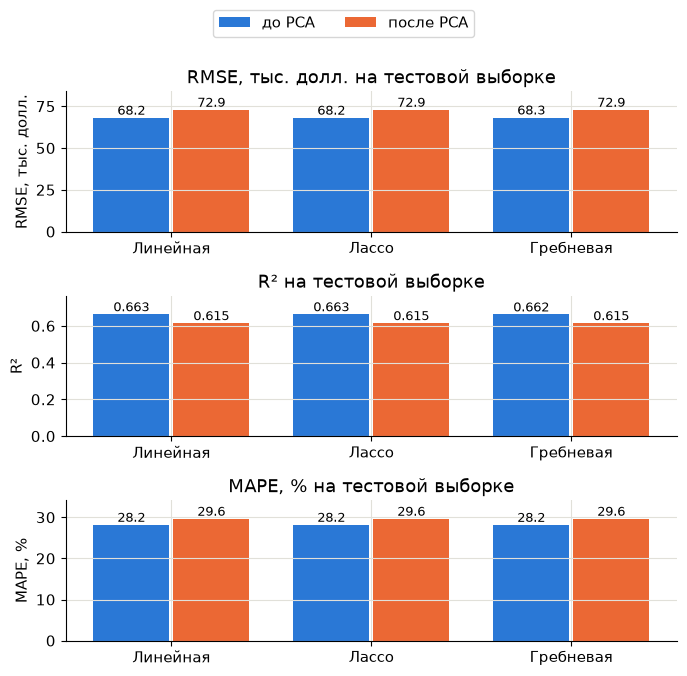

In [58]:
names = list(models)
x = np.arange(len(names))
fig, axes = plt.subplots(3, 1, figsize=(7, 6.3))
for ax, metric, divider, label, fmt in [(axes[0], 'RMSE', 1000, 'RMSE, тыс. долл.', '%.1f'),
                                        (axes[1], 'R2', 1, 'R²', '%.3f'),
                                        (axes[2], 'MAPE, %', 1, 'MAPE, %', '%.1f')]:
    bars_before = ax.bar(x - 0.2, before.loc[names, metric] / divider, width=0.38, color=BLUE, label='до PCA')
    bars_after = ax.bar(x + 0.2, after.loc[names, metric] / divider, width=0.38, color=ORANGE, label='после PCA')
    ax.bar_label(bars_before, fmt=fmt, fontsize=9)
    ax.bar_label(bars_after, fmt=fmt, fontsize=9)
    ax.set_xticks(x, names)
    ax.set_ylabel(label)
    ax.set_title(label + ' на тестовой выборке')
    ax.margins(y=0.15)
fig.legend(handles=[bars_before, bars_after], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()

Столбчатые диаграммы показывают то же самое: у всех трёх моделей после PCA столбцы выше по RMSE и MAPE и ниже по R². Внутри одной группы признаков три модели не отличаются, то есть регуляризация почти не влияет.

,"накопленная доля, %",RMSE CV,R2 CV
компонент,,,
1,48.6956,100254.5779,0.2389
2,72.5324,100189.8787,0.2398
3,85.9000,80828.3736,0.5053
4,96.2254,72781.6057,0.5989
5,98.1839,71056.8451,0.6177
6,99.2156,69084.3249,0.6386
7,99.8081,68980.6018,0.6397
8,100.0000,68976.3340,0.6398


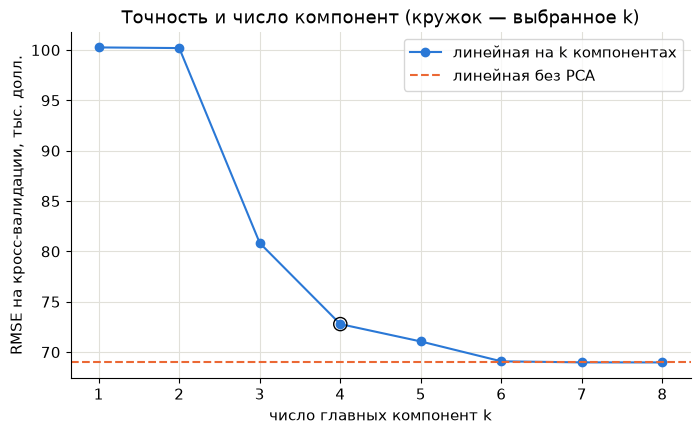

In [59]:
rows = []
for k in k_range:
    pipe_k = Pipeline([('prep', make_pca_preprocessor(k)), ('model', LinearRegression())])
    s = cross_validate(pipe_k, X_train, y_train, cv=cv, scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'})
    rows.append({'компонент': k, 'накопленная доля, %': cum_share[k - 1],
                 'RMSE CV': -s['test_rmse'].mean(), 'R2 CV': s['test_r2'].mean()})
k_curve = pd.DataFrame(rows).set_index('компонент')
display(k_curve.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_curve.index, k_curve['RMSE CV'] / 1000, marker='o', color=BLUE, label='линейная на k компонентах')
ax.axhline(cv_base.loc['Линейная', 'RMSE'] / 1000, color=ORANGE, ls='--', label='линейная без PCA')
ax.scatter(N_COMPONENTS, k_curve.loc[N_COMPONENTS, 'RMSE CV'] / 1000, s=90, facecolor='none',
           edgecolor='black', zorder=3)
ax.set_xlabel('число главных компонент k')
ax.set_ylabel('RMSE на кросс-валидации, тыс. долл.')
ax.set_title('Точность и число компонент (кружок — выбранное k)')
ax.legend()
plt.show()

Чтобы понять причину, линейную регрессию обучили на k = 1...8 компонентах (5-кратная кросс-валидация на train). При k = 1-2 RMSE около 100 тыс. долл., R² около 0,24, при k = 3 RMSE 80 828 (R² 0,505), при k = 4 (выбрано) 72 782 (R² 0,599), при k = 5 71 057, при k = 6 69 084 (R² 0,639), а при k = 8 68 976, как без PCA. Восемь компонент - это только поворот осей, поэтому прогнозы те же. Пятая и шестая компоненты объясняют 1,96 % и 1,03 % дисперсии, но заметно снижают ошибку. PCA выбирает направления по дисперсии признаков и не учитывает цель, поэтому малая доля дисперсии не значит малую пользу для прогноза. При 6 компонентах (99,2 % дисперсии) RMSE всего на 108 долл. больше, чем без PCA.

In [60]:
discarded = pd.DataFrame(pca_full.components_[N_COMPONENTS:].T, index=num_features,
                         columns=[f'PC{i}' for i in range(N_COMPONENTS + 1, len(eigenvalues) + 1)])
display(discarded.round(3))

,PC5,PC6,PC7,PC8
longitude,-0.090,0.470,-0.514,-0.051
latitude,-0.041,0.454,-0.531,-0.037
housing_median_age,-0.034,0.091,-0.043,0.003
total_rooms,-0.314,0.572,0.537,-0.158
total_bedrooms,-0.378,-0.226,-0.216,0.705
population,0.851,0.121,-0.018,0.132
households,-0.142,-0.411,-0.298,-0.674
median_income,0.056,-0.061,-0.167,0.043


Компонента PC5 (1,96 %) противопоставляет population (0,851) комнатам и спальням (-0,314 и -0,378). PC6 (1,03 %) складывает longitude и latitude (0,470 и 0,454) и противопоставляет total_rooms и households (0,572 и -0,411). Модель на исходных признаках использовала такие сочетания: коэффициенты longitude и latitude почти равны и оба отрицательные (-52 950 и -53 628), а у population и total_bedrooms они противоположных знаков (-40 333 и +42 827). При k = 4 эти направления отброшены, поэтому ошибка выросла. Часть сведений о местоположении перешла к INLAND, его коэффициент вырос по модулю с 39 120 до 71 480 долл.

#### 4.6.3. Остатки моделей на главных компонентах


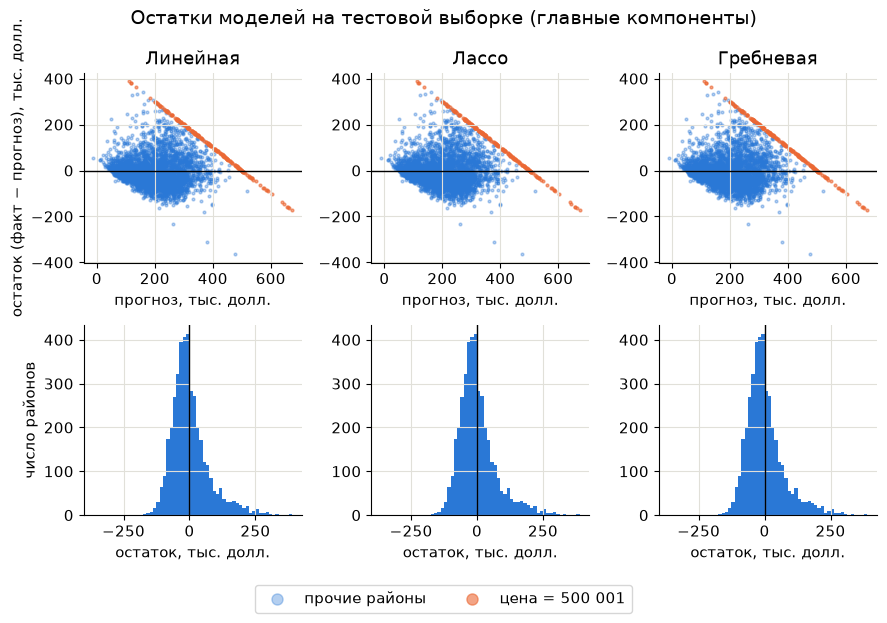

LM p-значение
модель    выборка                  
Линейная  train    590.3   2.8e-122
          test     181.2    5.8e-35
Лассо     train    590.3   2.8e-122
          test     181.2    5.8e-35
Гребневая train    590.3   2.8e-122
          test     181.2    5.8e-35

In [61]:
plot_residuals(models_pca, 'Остатки моделей на тестовой выборке (главные компоненты)')
bp_pca = bp_table(models_pca)
shown = bp_pca.copy()
shown['p-значение'] = shown['p-значение'].map('{:.1e}'.format)
display(shown.round(1))

Остатки на компонентах устроены так же: видны воронка и наклонная прямая из районов с ценой 500 001. Тест Бреуша-Пагана снова отвергает гомоскедастичность: LM = 590,3 на train и 181,2 на test, p-значения 2,8·10⁻¹²² и 5,8·10⁻³⁵. PCA убрал мультиколлинеарность, но не гетероскедастичность, значит, она не связана с корреляцией признаков. Разброс остатков ограничен снизу минимальной ценой.

#### 4.6.4. Как можно повысить точность


In [62]:
count_features = ['total_rooms', 'total_bedrooms', 'population', 'households']
other_features = [col for col in num_features if col not in count_features]
prep_log = ColumnTransformer([
    ('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())]), count_features),
    ('num', StandardScaler(), other_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_features),
])
pipe_log = Pipeline([('prep', prep_log), ('model', LinearRegression())])
cv_log = cv_table({'Линейная, log счётных признаков': pipe_log})
display(pd.concat([cv_base.loc[['Линейная']], cv_log]).round(4))

,RMSE,RMSE ±,R2,R2 ±,"MAPE, %","MAPE ±, %"
Линейная,68976.3340,1941.3818,0.6398,0.0103,28.7366,0.6933
"Линейная, log счётных признаков",66453.4892,1783.8609,0.6656,0.0110,28.0039,0.6818


Регуляризация не помогла. Счётные признаки скошены вправо (асимметрия 3,41-4,94), поэтому проверили одно простое изменение: логарифм ln(1 + x) четырёх счётных признаков (FunctionTransformer(np.log1p)) перед стандартизацией. На кросс-валидации RMSE снизилась с 68 976 до 66 453 долл. (-3,7 %), R² вырос с 0,640 до 0,666, а MAPE снизилась с 28,74 до 28,00 %. В основное сравнение до и после PCA этот вариант не включали, чтобы обе группы моделей работали на одних и тех же признаках. Дальше можно добавить относительные признаки или нелинейные модели.

In [63]:
summary = {
    'строк_всего': int(len(df)), 'столбцов': int(df.shape[1]),
    'числовых_столбцов': int((df.dtypes == 'float64').sum()),
    'пропусков_total_bedrooms': int(df['total_bedrooms'].isna().sum()),
    'дубликатов': int(df.duplicated().sum()),
    'частые_цены': {str(k): int(v) for k, v in df[TARGET].value_counts().head(3).items()},
    'частые_возрасты': {str(k): int(v) for k, v in df['housing_median_age'].value_counts().head(3).items()},
    'строк_с_выбросом': int(any_outlier.sum()),
    'комнат_на_домохозяйство_макс': float((df['total_rooms'] / df['households']).max()),
    'строк_после_пропусков': int(len(df.dropna())), 'противоречивых_строк': int(bad.sum()),
    'строк_после_очистки': int(len(df_clean)),
    'train': int(len(X_train)), 'test': int(len(X_test)),
    'средняя_цена_train': float(y_train.mean()), 'средняя_цена_test': float(y_test.mean()),
    'доля_среза_train': float((y_train == 500_001).mean() * 100),
    'доля_среза_test': float((y_test == 500_001).mean() * 100),
    'island_train': int((X_train['ocean_proximity'] == 'ISLAND').sum()),
    'island_test': int((X_test['ocean_proximity'] == 'ISLAND').sum()),
    'общих_районов_при_random_state_0': int(X_test.index.isin(X_test_other.index).sum()),
    'корр_с_соседом': float(neighbour_corr), 'доля_тех_же_координат': float(same_coords),
    'расхождение_пирсон_спирмен': float((corr - corr_s).abs().max().max()),
    'доход_выше_10_районов': int(rich.sum()),
    'доход_выше_10_доля_среза': float((y_train[rich] == 500_001).mean() * 100),
    'alpha_лассо': float(grid_lasso.best_params_['model__alpha']),
    'alpha_гребневая': float(grid_ridge.best_params_['model__alpha']),
    'итераций_лассо': int(grid_lasso.best_estimator_.named_steps['model'].n_iter_),
    'мин_цена': float(y.min()), 'районов_дешевле_50000': int((y < 50_000).sum()),
    'alpha_лассо_pca': float(grid_lasso_pca.best_params_['model__alpha']),
    'alpha_гребневая_pca': float(grid_ridge_pca.best_params_['model__alpha']),
    'отрицательных_прогнозов_test': int((y_pred_lin < 0).sum()),
    'мин_прогноз_test': float(y_pred_lin.min()),
    'остаток_среднее': float(resid_lin.mean()), 'остаток_медиана': float(resid_lin.median()),
    'остаток_макс': float(resid_lin.max()), 'остаток_мин': float(resid_lin.min()),
    'сумма_собственных_значений': float(eigenvalues.sum()),
    'число_компонент': N_COMPONENTS,
    'наибольшая_корр_компонент_test': float(off_diag),
}
summary

{'строк_всего': 20640,
 'столбцов': 10,
 'числовых_столбцов': 9,
 'пропусков_total_bedrooms': 207,
 'дубликатов': 0,
 'частые_цены': {'500001.0': 965, '137500.0': 122, '162500.0': 117},
 'частые_возрасты': {'52.0': 1273, '36.0': 862, '35.0': 824},
 'строк_с_выбросом': 3019,
 'комнат_на_домохозяйство_макс': 141.9090909090909,
 'строк_после_пропусков': 20433,
 'противоречивых_строк': 3,
 'строк_после_очистки': 20430,
 'train': 16344,
 'test': 4086,
 'средняя_цена_train': 206678.58266030348,
 'средняя_цена_test': 207607.75795398923,
 'доля_среза_train': 4.637787567302986,
 'доля_среза_test': 4.894762604013706,
 'island_train': 4,
 'island_test': 1,
 'общих_районов_при_random_state_0': 849,
 'корр_с_соседом': 0.8616791098739005,
 'доля_тех_же_координат': 54.91923641703378,
 'расхождение_пирсон_спирмен': 0.07403033471884984,
 'доход_выше_10_районов': 241,
 'доход_выше_10_доля_среза': 85.06224066390041,
 'alpha_лассо': 0.01,
 'alpha_гребневая': 31.622776601683793,
 'итераций_лассо': 405,
 'м

Основные числа выведены в ячейке выше (summary), таблицы и графики находятся в ячейках выше.

## 5. Заключение

Мы взяли набор California Housing Prices (Kaggle) с 20 640 районами Калифорнии и предсказывали median_house_value по восьми числовым признакам и ocean_proximity. Пропуски (207 в total_bedrooms) удалили вместе с 3 противоречивыми строками, осталось 20 430 наблюдений, которые разделили 80/20 на 16 344 и 4 086 района. Счётные признаки оказались скошены вправо (асимметрия до 4,94), а цена 500 001 долл. (965 районов) и возраст домов 52 года (1 273 района) оказались срезами. Выбросы по правилу 1,5·IQR (до 6,24 % значений признака) оставили. Признак ocean_proximity закодировали one-hot с базовой категорией <1H OCEAN, а числовые признаки стандартизовали внутри Pipeline.

Размерные признаки сильно коррелируют (r до 0,979, VIF до 35,00), у координат r = -0,925 и VIF 8,73 и 8,82. С ценой заметно связан только median_income (r = 0,686). Линейная, лассо и гребневая регрессии на исходных признаках дали почти одинаковое качество: на кросс-валидации RMSE около 68 970-68 976 долл., R² около 0,640, MAPE около 28,7 %, а на test у линейной RMSE = 68 157 долл., R² = 0,663, MAPE = 28,18 %. Alpha подобралось слабое (0,01 у лассо и 31,6 у гребневой), регуляризация результат не улучшила, а переобучения нет. Лучшей признали линейную модель как самую простую из равноценных. Остатки гетероскедастичны: СКО растёт с 42,5 до 83,8 тыс. долл. по мере роста прогноза, тест Бреуша-Пагана отвергает гомоскедастичность (p = 2,6·10⁻⁵⁹ на test), а на графиках видна наклонная полоса из районов со срезанной ценой.

После стандартизации в PCA выбрали 4 компоненты (96,2 % дисперсии), потому что превышен порог 90 % и есть излом на осыпи. Они отвечают за размер района, местоположение, доход и возраст застройки. Мультиколлинеарность устранена: корреляции компонент на test не больше 0,031, VIF = 1,0. Однако на компонентах все три модели стали хуже: test RMSE = 72 894 долл. (+6,8-7,0 %), R² = 0,615, MAPE = 29,64 %. PCA выбирает направления по дисперсии признаков, а не по связи с ценой, и в отброшенных компонентах оказались полезные для прогноза сочетания признаков. При 6 компонентах RMSE на кросс-валидации почти как у исходной (69 084 против 68 976). Логарифм счётных признаков снизил RMSE на кросс-валидации до 66 453 долл. (-3,7 %).

## 6. Список источников

1. Айвазян С. А., Бухштабер В. М., Енюков И. С., Мешалкин Л. Д. Прикладная статистика. Классификация и снижение размерности : справочное издание / под ред. С. А. Айвазяна. – Москва : Финансы и статистика, 1989. – 606, [1] с. – ISBN 5-279-00054-X.
2. Алетдинова А. А., Гриф М. Г. Системы искусственного интеллекта : учебное пособие. – Новосибирск : Изд-во НГТУ, 2023. – 73, [2] с. – ISBN 978-5-7782-5124-3.
3. Воронцов К. В. Математические методы обучения по прецедентам (теория обучения машин) : курс лекций. – [2011]. – 141 с. – URL: http://www.machinelearning.ru/wiki/images/6/6d/Voron-ML-1.pdf (дата обращения: 04.10.2026).
4. Джеймс Г., Уиттон Д., Хасти Т., Тибширани Р. Введение в статистическое обучение с примерами на языке R / пер. с англ. С. Э. Мастицкого. – 2-е изд., испр. – Москва : ДМК Пресс, 2017. – 455 с. – ISBN 978-5-97060-495-3.
5. Дрейпер Н. Р., Смит Г. Прикладной регрессионный анализ / пер. с англ. и ред. М. Власенко [и др.]. – 3-е изд. – Москва [и др.] : Диалектика, 2007. – 911 с. – (Теория вероятностей и математическая статистика). – ISBN 978-5-8459-0963-3.
6. Жерон О. Прикладное машинное обучение с помощью Scikit-Learn, Keras и TensorFlow : концепции, инструменты и техники для создания интеллектуальных систем / пер. с англ. Ю. Н. Артеменко. – Москва ; Санкт-Петербург : Диалектика, 2020. – 1039 с. – ISBN 978-5-907203-33-4. – Репозиторий с кодом и данными к книге: URL: https://github.com/ageron/handson-ml2 (дата обращения: 04.10.2026).
7. Магнус Я. Р., Катышев П. К., Пересецкий А. А. Эконометрика. Начальный курс : учебник. – 8-е изд., испр. – Москва : Дело, 2007. – 504 с. – ISBN 978-5-7749-0473-0.
8. Факторный, дискриминантный и кластерный анализ : сборник / Дж.-О. Ким, Ч. У. Мьюллер, У. Р. Клекка [и др.] ; пер. с англ. А. М. Хотинского, С. Б. Королева ; под ред. И. С. Енюкова. – Москва : Финансы и статистика, 1989. – 215 с. – ISBN 5-279-00247-X.
9. Jolliffe I. T. Principal Component Analysis. – 2nd ed. – New York : Springer, 2002. – (Springer Series in Statistics). – ISBN 0-387-95442-2. – DOI: 10.1007/b98835.
10. O'Brien R. M. A Caution Regarding Rules of Thumb for Variance Inflation Factors // Quality & Quantity. – 2007. – Vol. 41, № 5. – P. 673–690. – DOI: 10.1007/s11135-006-9018-6.
11. scikit-learn: machine learning in Python : документация. – URL: https://scikit-learn.org/stable/ (дата обращения: 04.10.2026).
12. statsmodels : документация. – URL: https://www.statsmodels.org/stable/ (дата обращения: 04.10.2026).


## 7. Приложение

Полный листинг кода находится в ячейках этого ноутбука. Репозиторий: https://github.com/SuLG-ik/nstu-ml-labs